# Kalp Hastalığı Sınıflandırması — Veri Hazırlama (Heart Disease UCI)

**Veri seti:** UCI Machine Learning Repository — Heart Disease (Cleveland alt kümesi).
Kaggle'daki *Heart Disease UCI* veri seti de bu kaynağa dayanır: 303 hasta kaydı, 14 sütun.

**Amaç:** Hastanın klinik ölçümlerinden kalp hastalığı olup olmadığını tahmin eden bir
sınıflandırma modeli kurmak. Bu notebook, modellemeden önceki hazırlık adımlarını içerir:

1. Veriyi pandas ile yükleme
2. Veriyi tanıma (sütunların anlamı, temel istatistikler)
3. Sınıf dengesi analizi (kaç "evet", kaç "hayır")
4. Veri temizleme (eksik değer kontrolü ve doldurma)
5. Kategorik değişkenlerin One-Hot Encoding ile sayısallaştırılması

---

## 0. Kütüphaneler ve ayarlar

In [1]:
import os

import numpy as np
import pandas as pd

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 60)

print("pandas sürümü:", pd.__version__)
print("numpy  sürümü:", np.__version__)

pandas sürümü: 3.1.1
numpy  sürümü: 2.5.4


## 1. Veri setini yükleme

Veri önce proje içindeki yerel dosyadan (`data/processed.cleveland.data`) okunur;
dosya yoksa doğrudan UCI arşivindeki URL'den çekilir. Böylece notebook her ortamda çalışır.

Ham dosyanın **sütun başlığı yoktur**, bu yüzden sütun adlarını UCI dokümantasyonundaki
sıraya göre kendimiz veriyoruz. Eksik değerler dosyada `?` karakteriyle gösterilmiş;
`na_values=["?"]` ile bunları pandas'ın `NaN` değerine çeviriyoruz.

In [2]:
COLUMNS = [
    "age", "sex", "cp", "trestbps", "chol", "fbs", "restecg",
    "thalach", "exang", "oldpeak", "slope", "ca", "thal", "num",
]

LOCAL_PATH = "data/processed.cleveland.data"
UCI_URL = (
    "https://archive.ics.uci.edu/ml/machine-learning-databases/"
    "heart-disease/processed.cleveland.data"
)

source = LOCAL_PATH if os.path.exists(LOCAL_PATH) else UCI_URL

df = pd.read_csv(source, header=None, names=COLUMNS, na_values=["?"])

print("Veri kaynağı :", source)
print("Satır sayısı :", df.shape[0])
print("Sütun sayısı :", df.shape[1])
df.head()

Veri kaynağı : data/processed.cleveland.data
Satır sayısı : 303
Sütun sayısı : 14


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


## 2. Veriyi tanıma

### 2.1 Sütunların anlamı

| Sütun | Anlamı | Tür | Değerler |
|---|---|---|---|
| `age` | Hastanın yaşı (yıl) | Sayısal | 29 – 77 |
| `sex` | Cinsiyet | Kategorik (ikili) | 1 = erkek, 0 = kadın |
| `cp` | Göğüs ağrısı tipi (*chest pain*) | Kategorik | 1 = tipik anjina, 2 = atipik anjina, 3 = anjina dışı ağrı, 4 = asemptomatik |
| `trestbps` | Dinlenme halinde kan basıncı (mm Hg) | Sayısal | 94 – 200 |
| `chol` | Serum kolesterol (mg/dl) | Sayısal | 126 – 564 |
| `fbs` | Açlık kan şekeri > 120 mg/dl mi? | Kategorik (ikili) | 1 = evet, 0 = hayır |
| `restecg` | Dinlenme EKG sonucu | Kategorik | 0 = normal, 1 = ST-T dalga anormalliği, 2 = sol ventrikül hipertrofisi |
| `thalach` | Egzersizde ulaşılan maksimum kalp hızı | Sayısal | 71 – 202 |
| `exang` | Egzersize bağlı anjina | Kategorik (ikili) | 1 = var, 0 = yok |
| `oldpeak` | Egzersizin dinlenmeye göre oluşturduğu ST çökmesi | Sayısal | 0.0 – 6.2 |
| `slope` | Egzersiz ST segmentinin eğimi | Kategorik | 1 = yukarı eğimli, 2 = düz, 3 = aşağı eğimli |
| `ca` | Floroskopide boyanan ana damar sayısı | Sayısal (sayım, 0–3) | 0, 1, 2, 3 |
| `thal` | Talyum (talasemi) stres testi sonucu | Kategorik | 3 = normal, 6 = sabit defekt, 7 = geri dönüşlü defekt |
| `num` | **Hedef değişken** — kalp hastalığı tanısı | Kategorik (sıralı) | 0 = hastalık yok, 1–4 = hastalık var (damar daralması şiddeti) |

> **Not:** Kodlamalar orijinal UCI şemasına göre verilmiştir. Kaggle'da dolaşan bazı
> türevlerde `cp`, `restecg`, `slope` ve `thal` sıfırdan başlayacak şekilde yeniden
> numaralandırılmıştır; bu notebook ham UCI kodlamasını kullanır.

### 2.2 Veri tipleri ve temel istatistikler

In [3]:
print("=== Veri tipleri ve dolu kayıt sayıları ===")
df.info()

=== Veri tipleri ve dolu kayıt sayıları ===
<class 'pandas.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    float64
 1   sex       303 non-null    float64
 2   cp        303 non-null    float64
 3   trestbps  303 non-null    float64
 4   chol      303 non-null    float64
 5   fbs       303 non-null    float64
 6   restecg   303 non-null    float64
 7   thalach   303 non-null    float64
 8   exang     303 non-null    float64
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    float64
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  num       303 non-null    int64  
dtypes: float64(13), int64(1)
memory usage: 33.3 KB


In [4]:
print("=== Sayısal özet istatistikler ===")
df.describe().T

=== Sayısal özet istatistikler ===


,count,mean,std,min,25%,50%,75%,max
age,303.0,54.438944,9.038662,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.679868,0.467299,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.158416,0.960126,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.689769,17.599748,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.693069,51.776918,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.148515,0.356198,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.990099,0.994971,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.607261,22.875003,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.326733,0.469794,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.039604,1.161075,0.0,0.0,0.8,1.6,6.2


In [5]:
# Kategorik olarak değerlendireceğimiz sütunların benzersiz değerleri
for kolon in ["sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal", "num"]:
    degerler = sorted(df[kolon].dropna().unique().tolist())
    print(f"{kolon:9s} -> {degerler}")

sex       -> [0.0, 1.0]
cp        -> [1.0, 2.0, 3.0, 4.0]
fbs       -> [0.0, 1.0]
restecg   -> [0.0, 1.0, 2.0]
exang     -> [0.0, 1.0]
slope     -> [1.0, 2.0, 3.0]
ca        -> [0.0, 1.0, 2.0, 3.0]
thal      -> [3.0, 6.0, 7.0]
num       -> [0, 1, 2, 3, 4]


## 3. Sınıf dengesi

Hedef sütun `num` 0–4 arasında değer alır ve hastalığın **şiddetini** gösterir.
Problemimiz "kalp hastalığı var mı / yok mu" şeklinde **ikili sınıflandırma** olduğu için
yeni bir `target` sütunu üretiyoruz:

- `num == 0`  →  `target = 0` (hastalık **yok** / "hayır")
- `num >= 1`  →  `target = 1` (hastalık **var** / "evet")

In [6]:
df["target"] = (df["num"] > 0).astype(int)

sayim = df["target"].value_counts().sort_index()
oran = df["target"].value_counts(normalize=True).sort_index() * 100

etiket = {0: "HAYIR (hastalık yok)", 1: "EVET  (hastalık var)"}

print("=== Hedef değişkenin sınıf dağılımı ===")
for sinif in sayim.index:
    print(f"{etiket[sinif]:24s}: {sayim[sinif]:4d} hasta  (%{oran[sinif]:.2f})")
print(f"{'TOPLAM':24s}: {sayim.sum():4d} hasta")

=== Hedef değişkenin sınıf dağılımı ===
HAYIR (hastalık yok)    :  164 hasta  (%54.13)
EVET  (hastalık var)    :  139 hasta  (%45.87)
TOPLAM                  :  303 hasta


In [7]:
# Dengesizlik oranı = çoğunluk sınıfı / azınlık sınıfı
dengesizlik = sayim.max() / sayim.min()

print(f"Çoğunluk sınıfı  : {etiket[sayim.idxmax()]} ({sayim.max()} hasta)")
print(f"Azınlık sınıfı   : {etiket[sayim.idxmin()]} ({sayim.min()} hasta)")
print(f"Dengesizlik oranı: {dengesizlik:.2f} : 1")
print()

if dengesizlik < 1.5:
    print("SONUÇ: Sınıflar DENGELİ kabul edilebilir.")
    print("  -> Dengesizlik oranı 1.5'in altında; her iki sınıf da verinin %40'ından fazlasını kapsıyor.")
    print("  -> SMOTE / class_weight gibi dengeleme tekniklerine gerek yok.")
    print("  -> Yine de accuracy tek başına yeterli değil; precision, recall, F1 ve ROC-AUC")
    print("     birlikte raporlanmalı (tıbbi teşhiste hasta olanı kaçırmamak, yani recall, kritiktir).")
elif dengesizlik < 3:
    print("SONUÇ: Sınıflar ILIMLI DENGESİZ. class_weight='balanced' denenebilir.")
else:
    print("SONUÇ: Sınıflar CİDDİ DENGESİZ. Yeniden örnekleme (SMOTE vb.) gerekir.")

Çoğunluk sınıfı  : HAYIR (hastalık yok) (164 hasta)
Azınlık sınıfı   : EVET  (hastalık var) (139 hasta)
Dengesizlik oranı: 1.18 : 1

SONUÇ: Sınıflar DENGELİ kabul edilebilir.
  -> Dengesizlik oranı 1.5'in altında; her iki sınıf da verinin %40'ından fazlasını kapsıyor.
  -> SMOTE / class_weight gibi dengeleme tekniklerine gerek yok.
  -> Yine de accuracy tek başına yeterli değil; precision, recall, F1 ve ROC-AUC
     birlikte raporlanmalı (tıbbi teşhiste hasta olanı kaçırmamak, yani recall, kritiktir).


In [8]:
# Orijinal 5 sınıflı dağılım: ikiliye indirgemeden önce nasıl görünüyordu?
siddet_etiket = {
    0: "0 - hastalık yok",
    1: "1 - hafif",
    2: "2 - orta",
    3: "3 - ileri",
    4: "4 - çok ileri",
}
print("=== Orijinal 'num' sütununun 5 sınıflı dağılımı ===")
for sinif, adet in df["num"].value_counts().sort_index().items():
    print(f"{siddet_etiket[sinif]:18s}: {adet:4d} hasta")
print()
print("Not: 1-4 sınıfları tek tek çok az örnek içerdiği için (13-55 hasta),")
print("5 sınıflı sınıflandırma yerine ikili sınıflandırma daha sağlıklı sonuç verir.")

=== Orijinal 'num' sütununun 5 sınıflı dağılımı ===
0 - hastalık yok  :  164 hasta
1 - hafif         :   55 hasta
2 - orta          :   36 hasta
3 - ileri         :   35 hasta
4 - çok ileri     :   13 hasta

Not: 1-4 sınıfları tek tek çok az örnek içerdiği için (13-55 hasta),
5 sınıflı sınıflandırma yerine ikili sınıflandırma daha sağlıklı sonuç verir.


## 4. Veri temizleme — eksik değerler

Ham dosyada eksik değerler `?` ile işaretlenmişti; yükleme sırasında `NaN`'a çevirdik.
Şimdi hangi sütunlarda ne kadar eksik olduğunu kontrol edelim.

In [9]:
eksik_sayi = df.isna().sum()
eksik_yuzde = (eksik_sayi / len(df) * 100).round(2)

eksik_tablo = pd.DataFrame({"eksik_adet": eksik_sayi, "eksik_yuzde": eksik_yuzde})
eksik_tablo = eksik_tablo[eksik_tablo["eksik_adet"] > 0].sort_values(
    "eksik_adet", ascending=False
)

print("=== Eksik değer içeren sütunlar ===")
if eksik_tablo.empty:
    print("Hiç eksik değer yok.")
else:
    print(eksik_tablo)
    print()
    print("Eksik değer içeren satır sayısı:", int(df.isna().any(axis=1).sum()),
          f"/ {len(df)}  (%{df.isna().any(axis=1).mean() * 100:.2f})")

=== Eksik değer içeren sütunlar ===
      eksik_adet  eksik_yuzde
ca             4         1.32
thal           2         0.66

Eksik değer içeren satır sayısı: 6 / 303  (%1.98)


### Hangi yöntemi seçtik ve neden?

Eksik değerler yalnızca iki sütunda ve çok az sayıda kayıtta (toplam 6 satır, verinin ~%2'si).

- **Satırları silmek** (`dropna`) mümkündü, ancak 303 satırlık küçük bir veri setinde
  6 hastayı atmak gereksiz bilgi kaybı olur.
- **Ortalama ile doldurmak** uygun değil: `ca` bir *sayım* (0–3), `thal` ise *kategorik*
  bir koddur (3/6/7). Ortalama (ör. 4.73) bu sütunlarda anlamsız, var olmayan bir değer üretir.
- **Seçilen yöntem: mod (en sık görülen değer) ile doldurma.** Her iki sütun da ayrık
  değerler aldığı için mod, var olan geçerli kategorilerden birini atar ve dağılımı bozmaz.

In [10]:
df_temiz = df.copy()

for kolon in ["ca", "thal"]:
    if df_temiz[kolon].isna().any():
        mod_deger = df_temiz[kolon].mode()[0]
        adet = int(df_temiz[kolon].isna().sum())
        df_temiz[kolon] = df_temiz[kolon].fillna(mod_deger)
        print(f"'{kolon}' sütunundaki {adet} eksik değer mod ile dolduruldu -> {mod_deger}")

print()
print("Doldurma sonrası kalan eksik değer sayısı:", int(df_temiz.isna().sum().sum()))
print("Satır sayısı korundu mu?", df_temiz.shape[0] == df.shape[0], f"({df_temiz.shape[0]} satır)")

'ca' sütunundaki 4 eksik değer mod ile dolduruldu -> 0.0
'thal' sütunundaki 2 eksik değer mod ile dolduruldu -> 3.0

Doldurma sonrası kalan eksik değer sayısı: 0
Satır sayısı korundu mu? True (303 satır)


In [11]:
# Yinelenen (tekrar eden) satır kontrolü
yinelenen = int(df_temiz.duplicated().sum())
print("Yinelenen satır sayısı:", yinelenen)
if yinelenen > 0:
    df_temiz = df_temiz.drop_duplicates().reset_index(drop=True)
    print("Yinelenen satırlar silindi. Yeni satır sayısı:", df_temiz.shape[0])
else:
    print("Temizlenecek yinelenen satır yok.")

Yinelenen satır sayısı: 0
Temizlenecek yinelenen satır yok.


## 5. Kategorik değişkenlerin sayısallaştırılması (One-Hot Encoding)

Sütunları üç gruba ayırıyoruz, çünkü her gruba farklı davranmak gerekir:

| Grup | Sütunlar | İşlem | Gerekçe |
|---|---|---|---|
| **Sayısal (sürekli)** | `age`, `trestbps`, `chol`, `thalach`, `oldpeak`, `ca` | Değişiklik yok | Değerler arasındaki büyüklük ilişkisi anlamlı |
| **İkili kategorik** | `sex`, `fbs`, `exang` | Değişiklik yok (0/1 `int`) | Zaten 0/1; One-Hot gereksiz sütun üretir |
| **Çok sınıflı kategorik** | `cp`, `restecg`, `slope`, `thal` | **One-Hot Encoding** | Kodlar arasında sıralama yok; sayı olarak bırakılırsa model yanlış sıralama öğrenir |

**Neden `cp` sayı olarak bırakılmaz?** `cp` değerleri 1, 2, 3, 4 kodlarından oluşur ama
"asemptomatik (4)" ile "tipik anjina (1)" arasında `4 > 1` gibi bir büyüklük ilişkisi yoktur.
Sayısal bırakılırsa model bunu sanki artan bir şiddet ölçeğiymiş gibi yorumlar. One-Hot
Encoding her kategori için ayrı bir 0/1 sütunu üretir ve bu yapay sıralamayı ortadan kaldırır.

`ca` sütunu ise gerçek bir **sayım** (0, 1, 2, 3 damar) olduğu için sayısal bırakıldı —
burada büyüklük ilişkisi anlamlı.

In [12]:
SAYISAL = ["age", "trestbps", "chol", "thalach", "oldpeak", "ca"]
IKILI = ["sex", "fbs", "exang"]
KATEGORIK = ["cp", "restecg", "slope", "thal"]

X_ham = df_temiz[SAYISAL + IKILI + KATEGORIK].copy()
y = df_temiz["target"].copy()

# İkili sütunları float -> int'e çevir (0.0/1.0 yerine 0/1)
for kolon in IKILI:
    X_ham[kolon] = X_ham[kolon].astype(int)

# Kategorik sütunları tam sayıya çevir ki sütun adları cp_1.0 değil cp_1 olsun
for kolon in KATEGORIK:
    X_ham[kolon] = X_ham[kolon].astype(int)

print("One-Hot Encoding öncesi:", X_ham.shape)
X_ham.head()

One-Hot Encoding öncesi: (303, 13)


,age,trestbps,chol,thalach,oldpeak,ca,sex,fbs,exang,cp,restecg,slope,thal
0,63.0,145.0,233.0,150.0,2.3,0.0,1,1,0,1,2,3,6
1,67.0,160.0,286.0,108.0,1.5,3.0,1,0,1,4,2,2,3
2,67.0,120.0,229.0,129.0,2.6,2.0,1,0,1,4,2,2,7
3,37.0,130.0,250.0,187.0,3.5,0.0,1,0,0,3,0,3,3
4,41.0,130.0,204.0,172.0,1.4,0.0,0,0,0,2,2,1,3


In [13]:
X = pd.get_dummies(
    X_ham,
    columns=KATEGORIK,
    prefix=KATEGORIK,
    drop_first=False,   # ağaç tabanlı modeller için tüm kategoriler kalsın
    dtype=int,          # True/False yerine 1/0
)

print("One-Hot Encoding sonrası:", X.shape)
print(f"{len(KATEGORIK)} kategorik sütun -> "
      f"{X.shape[1] - len(SAYISAL) - len(IKILI)} adet 0/1 sütununa dönüştü")
print()
print("Yeni sütunlar:")
for kolon in X.columns:
    print("  -", kolon)

One-Hot Encoding sonrası: (303, 22)
4 kategorik sütun -> 13 adet 0/1 sütununa dönüştü

Yeni sütunlar:
  - age
  - trestbps
  - chol
  - thalach
  - oldpeak
  - ca
  - sex
  - fbs
  - exang
  - cp_1
  - cp_2
  - cp_3
  - cp_4
  - restecg_0
  - restecg_1
  - restecg_2
  - slope_1
  - slope_2
  - slope_3
  - thal_3
  - thal_6
  - thal_7


In [14]:
X.head()

,age,trestbps,chol,thalach,oldpeak,ca,sex,fbs,exang,cp_1,cp_2,cp_3,cp_4,restecg_0,restecg_1,restecg_2,slope_1,slope_2,slope_3,thal_3,thal_6,thal_7
0,63.0,145.0,233.0,150.0,2.3,0.0,1,1,0,1,0,0,0,0,0,1,0,0,1,0,1,0
1,67.0,160.0,286.0,108.0,1.5,3.0,1,0,1,0,0,0,1,0,0,1,0,1,0,1,0,0
2,67.0,120.0,229.0,129.0,2.6,2.0,1,0,1,0,0,0,1,0,0,1,0,1,0,0,0,1
3,37.0,130.0,250.0,187.0,3.5,0.0,1,0,0,0,0,1,0,1,0,0,0,0,1,1,0,0
4,41.0,130.0,204.0,172.0,1.4,0.0,0,0,0,0,1,0,0,0,0,1,1,0,0,1,0,0


> **`drop_first` hakkında:** Burada `drop_first=False` kullandık; her kategori kendi
> sütununu koruyor. Bu, ağaç tabanlı modeller (Random Forest, Gradient Boosting) ve
> özellik önemi yorumlaması için daha okunabilir. Lojistik regresyon gibi doğrusal
> modellerde tam eş-doğrusallık (*dummy variable trap*) yaratmamak için
> `drop_first=True` tercih edilebilir.

### Doğrulama: veri artık modele hazır mı?

In [15]:
print("=== Doğrulama kontrolleri ===")

tumu_sayisal = all(np.issubdtype(t, np.number) for t in X.dtypes)
print(f"1) Tüm sütunlar sayısal mı?        : {tumu_sayisal}")
print(f"2) Eksik değer kaldı mı?           : {int(X.isna().sum().sum())} eksik değer")
print(f"3) Özellik matrisi (X) boyutu      : {X.shape}")
print(f"4) Hedef vektörü (y) boyutu        : {y.shape}")
print(f"5) X ve y satır sayısı uyumlu mu?  : {len(X) == len(y)}")
print(f"6) Hedef sınıf dağılımı            : {y.value_counts().sort_index().to_dict()}")
print()
print("=== Son veri tipleri ===")
print(X.dtypes.value_counts())

=== Doğrulama kontrolleri ===
1) Tüm sütunlar sayısal mı?        : True
2) Eksik değer kaldı mı?           : 0 eksik değer
3) Özellik matrisi (X) boyutu      : (303, 22)
4) Hedef vektörü (y) boyutu        : (303,)
5) X ve y satır sayısı uyumlu mu?  : True
6) Hedef sınıf dağılımı            : {0: 164, 1: 139}

=== Son veri tipleri ===
int64      16
float64     6
Name: count, dtype: int64


## 6. Hazırlanan veriyi kaydet

İşlenmiş veriyi diske yazıyoruz ki modelleme adımı (train/test ayrımı, ölçeklendirme,
model eğitimi) bu notebook'u yeniden çalıştırmak zorunda kalmadan buradan devam edebilsin.

In [16]:
os.makedirs("outputs", exist_ok=True)

islenmis = X.copy()
islenmis["target"] = y

cikti_yolu = "outputs/heart_processed.csv"
islenmis.to_csv(cikti_yolu, index=False)

print(f"Kaydedildi: {cikti_yolu}")
print(f"Boyut     : {islenmis.shape[0]} satır x {islenmis.shape[1]} sütun "
      f"({X.shape[1]} özellik + 1 hedef)")

Kaydedildi: outputs/heart_processed.csv
Boyut     : 303 satır x 23 sütun (22 özellik + 1 hedef)


## 7. Görselleştirme

Bu bölümde altı grafik var; her birinin altında grafiğin **hastalık durumu üzerindeki
etkisini** okuyan kısa bir yorum hücresi bulunuyor.

**Renk ve biçim kararları** (grafikler arasında tutarlı olması için):

- **Mavi = hastalık YOK, turuncu = hastalık VAR.** Bu iki renk tüm notebook boyunca
  aynı anlamı taşır. Yeşil/kırmızı ikilisi semantik olarak daha cazip olsa da
  deuteranopi (kırmızı-yeşil renk körlüğü) altında birbirine karışıyor, bu yüzden
  kullanılmadı.
- **Oran grafikleri tek renkte** (turuncu), çünkü orada renk bir kimlik değil; uzunluk
  zaten değeri gösteriyor. Kategorileri değerine göre renklendirmek bilgiyi iki kez
  kodlamak olurdu.
- **Korelasyon matrisi diverging** (mavi ↔ gri ↔ kırmızı): işaretin yönü önemli
  olduğu için nötr gri bir orta nokta ve zıt okunan iki kutup kullanıldı. Gökkuşağı
  renk skalası değerleri yanlış okutur.
- Her grafikte değerler doğrudan etiket olarak yazıldı; yani hiçbir bilgi yalnızca
  renge bağlı değil.

In [17]:
%matplotlib inline
import itertools
import logging

import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import BoxStyle, FancyBboxPatch, Rectangle

# --- Renk paleti (doğrulanmış) ---------------------------------------------
SURFACE = "#fcfcfb"   # grafik zemini
INK = "#0b0b0b"       # birincil metin
INK_2 = "#52514e"     # ikincil metin
MUTED = "#898781"     # eksen / tik etiketleri
GRID = "#e1e0d9"      # kılcal ızgara
AXIS = "#c3c2b7"      # taban / eksen çizgisi

C_YOK = "#2a78d6"     # hastalık YOK  (kategorik slot 1 - mavi)
C_VAR = "#eb6834"     # hastalık VAR  (kategorik slot 2 - turuncu)

DIV_NEG = "#2a78d6"   # diverging: negatif kutup (mavi)
DIV_MID = "#f0efec"   # diverging: nötr orta nokta (gri)
DIV_POS = "#e34948"   # diverging: pozitif kutup (kırmızı)

CMAP_DIV = LinearSegmentedColormap.from_list("mavi_gri_kirmizi",
                                             [DIV_NEG, DIV_MID, DIV_POS])

plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": "figure",
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "font.family": ["Segoe UI", "DejaVu Sans"],
    "font.size": 10,
    "axes.labelcolor": INK_2,
    "axes.edgecolor": AXIS,
    "text.color": INK,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "grid.color": GRID,
    "grid.linewidth": 1.0,
    "grid.linestyle": "-",
    "axes.grid": False,
    "legend.frameon": False,
})

# matplotlib, 'semibold' ağırlığını yedek yazı tipi DejaVu Sans'ta bulamadığında
# tek seferlik bir uyarı basar. Grafiklerde Segoe UI Semibold kullanıldığı için
# çıktıyı etkilemiyor; yalnızca not defterini kirletmesin diye susturuyoruz.
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)

FIG_DIZIN = "outputs/figures"
os.makedirs(FIG_DIZIN, exist_ok=True)

# Okunabilir Türkçe değişken adları
AD = {
    "age": "Yaş",
    "sex": "Cinsiyet (1=erkek)",
    "cp": "Göğüs ağrısı tipi",
    "trestbps": "Dinlenme kan basıncı",
    "chol": "Kolesterol",
    "fbs": "Açlık kan şekeri >120",
    "restecg": "Dinlenme EKG",
    "thalach": "Maks. kalp atış hızı",
    "exang": "Egzersiz anjinası",
    "oldpeak": "ST çökmesi (oldpeak)",
    "slope": "ST eğimi",
    "ca": "Boyanan damar sayısı",
    "thal": "Talyum testi",
    "target": "Hedef (hastalık)",
}
CP_AD = {1: "Tipik anjina", 2: "Atipik anjina", 3: "Anjina dışı ağrı", 4: "Asemptomatik"}

print("Görselleştirme ayarları hazır. Şekiller şuraya da kaydedilecek:", FIG_DIZIN)

Görselleştirme ayarları hazır. Şekiller şuraya da kaydedilecek: outputs/figures


In [18]:
# --- Yardımcı çizim fonksiyonları -----------------------------------------

def eksen(gen, yuk, sol=0.26, sag=0.97, alt=0.17, ust=0.78):
    # Tek eksenli, sabit yerleşimli bir figür kurar (zemin + kılcal çerçeve).
    fig = plt.figure(figsize=(gen, yuk), facecolor=SURFACE)
    ax = fig.add_axes([sol, alt, sag - sol, ust - alt])
    ax.set_facecolor(SURFACE)
    for yan in ("top", "right"):
        ax.spines[yan].set_visible(False)
    for yan in ("left", "bottom"):
        ax.spines[yan].set_color(AXIS)
        ax.spines[yan].set_linewidth(1.0)
    ax.tick_params(colors=MUTED, length=0, labelsize=9.5)
    ax.set_axisbelow(True)
    return fig, ax


def baslik(fig, ana, alt_metin=None):
    # Sola hizalı başlık + ikincil renkte alt başlık.
    # Konumlar piksel cinsinden hesaplanır, böylece figür boyu değişse de
    # başlık ile alt başlık arasındaki boşluk sabit kalır.
    yuk_px = fig.get_figheight() * fig.dpi
    fig.text(0.015, 1 - 14 / yuk_px, ana, ha="left", va="top",
             fontsize=12.5, color=INK, fontweight="semibold")
    if alt_metin:
        fig.text(0.015, 1 - 38 / yuk_px, alt_metin, ha="left", va="top",
                 fontsize=9.5, color=INK_2)


def _px_birim(ax):
    # Eksende 1 pikselin kaç veri birimine karşılık geldiğini döndürür.
    fig = ax.figure
    pos = ax.get_position()
    w_px = fig.get_figwidth() * fig.dpi * pos.width
    h_px = fig.get_figheight() * fig.dpi * pos.height
    x0, x1 = ax.get_xlim()
    y0, y1 = ax.get_ylim()
    return abs(x1 - x0) / w_px, abs(y1 - y0) / h_px


def cubuk_yatay(ax, y, deger, renk, taban=0.0, kalinlik_px=24, yaricap_px=4):
    # Veri ucu 4px yuvarlatılmış, taban kenarı kare yatay çubuk.
    # Çubuk tabanın ötesine taşacak şekilde çizilir, sonra tabana kırpılır;
    # böylece yuvarlatma yalnızca veri ucunda kalır. Kalınlık 24px ile
    # sınırlı (bant içinde nefes payı bırakmak için).
    if abs(deger - taban) < 1e-12:
        return
    dx, dy = _px_birim(ax)
    kalinlik = min(kalinlik_px * dy, 0.62)
    r = yaricap_px * dx
    yon = 1.0 if deger >= taban else -1.0
    x_bas = taban - yon * r

    kutu = FancyBboxPatch(
        (min(x_bas, deger), y - kalinlik / 2.0),
        abs(deger - x_bas), kalinlik,
        boxstyle=BoxStyle("Round", pad=0, rounding_size=r),
        mutation_aspect=dy / dx,
        linewidth=0, facecolor=renk, zorder=3,
    )
    ax.add_patch(kutu)
    kirp = Rectangle((min(taban, deger), y - kalinlik), abs(deger - taban),
                     kalinlik * 2.0, transform=ax.transData)
    kutu.set_clip_path(kirp)


def kaydet(fig, ad):
    yol = f"{FIG_DIZIN}/{ad}.png"
    fig.savefig(yol, facecolor=SURFACE, edgecolor="none")
    return yol

print("Yardımcı fonksiyonlar tanımlandı.")

Yardımcı fonksiyonlar tanımlandı.


### Grafik 1 — Hedef değişkenin genel dağılımı

Sınıf       Hasta sayısı     Pay
Hastalık YOK      164      %54.13
Hastalık VAR      139      %45.87
TOPLAM            303      %100.00


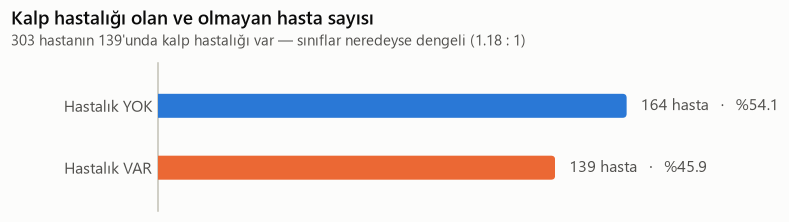

In [19]:
sayim = df_temiz["target"].value_counts().sort_index()
oran = df_temiz["target"].value_counts(normalize=True).sort_index() * 100
adlar = ["Hastalık YOK", "Hastalık VAR"]
renkler = [C_YOK, C_VAR]

# Tablo görünümü: grafikteki her değer sayı olarak da okunabilir
print("Sınıf       Hasta sayısı     Pay")
for i, ad in enumerate(adlar):
    print(f"{ad:12s} {int(sayim.iloc[i]):8d}      %{oran.iloc[i]:.2f}")
print(f"{'TOPLAM':12s} {int(sayim.sum()):8d}      %100.00")

fig, ax = eksen(7.2, 2.5, sol=0.20, sag=0.97, alt=0.22, ust=0.76)
ax.set_xlim(0, sayim.max() * 1.30)
ax.set_ylim(-0.7, 1.7)

y_pos = [1, 0]  # üstte YOK, altta VAR
for i in range(2):
    deger = int(sayim.iloc[i])
    cubuk_yatay(ax, y_pos[i], deger, renkler[i])
    ax.text(deger + sayim.max() * 0.03, y_pos[i],
            f"{deger} hasta   ·   %{oran.iloc[i]:.1f}",
            va="center", ha="left", fontsize=10.5, color=INK_2)

ax.set_yticks(y_pos)
ax.set_yticklabels(adlar)
ax.tick_params(axis="y", labelcolor=INK_2, labelsize=10.5)
ax.set_xticks([])
ax.spines["bottom"].set_visible(False)

baslik(fig,
       "Kalp hastalığı olan ve olmayan hasta sayısı",
       "303 hastanın 139'unda kalp hastalığı var — sınıflar neredeyse dengeli (1.18 : 1)")
kaydet(fig, "g1_hedef_dagilimi")
plt.show()

**Yorum.** Veri setinde **164 sağlıklı (%54.1)** ve **139 hastalıklı (%45.9)** kayıt var;
dengesizlik oranı yalnızca **1.18 : 1**. Bunun sonuca etkisi şudur: model "herkes sağlıklı"
diye tahmin ederek en fazla **%54 doğruluk** alabilir — yani anlamlı bir modelin bu temel
çizgiyi (*baseline*) açık ara geçmesi gerekir. Sınıflar dengeli olduğu için SMOTE gibi
yeniden örnekleme tekniklerine gerek yok ve `accuracy` metriği (dengesiz verilerde olduğu
gibi) yanıltıcı olmayacak. Yine de tıbbi bağlamda hasta olanı kaçırmamak kritik olduğundan
**recall** birincil metrik olarak izlenmeli.

### Grafik 2 — Cinsiyete göre kalp hastalığı oranı

Cinsiyet  Toplam  Hasta   Oran
Kadın        97     25   %25.77
Erkek       206    114   %55.34
Genel ortalama: %45.87


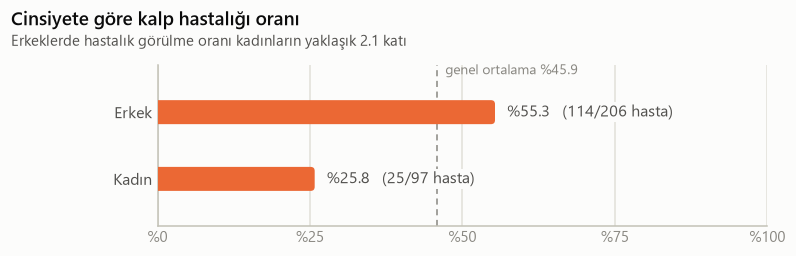

In [20]:
cins = df_temiz.groupby("sex")["target"].agg(["size", "sum", "mean"])
cins.index = ["Kadın", "Erkek"]            # sex: 0 = kadın, 1 = erkek
cins["oran_%"] = (cins["mean"] * 100).round(2)
cins = cins.sort_values("mean")            # düşükten yükseğe sırala

genel_oran = df_temiz["target"].mean() * 100

print("Cinsiyet  Toplam  Hasta   Oran")
for ad, satir in cins.iterrows():
    print(f"{ad:8s} {int(satir['size']):6d} {int(satir['sum']):6d}   %{satir['oran_%']:.2f}")
print(f"Genel ortalama: %{genel_oran:.2f}")

fig, ax = eksen(7.2, 2.6, sol=0.20, sag=0.97, alt=0.20, ust=0.76)
ax.set_xlim(0, 100)
ax.set_ylim(-0.7, 1.7)
ax.xaxis.grid(True, color=GRID, linewidth=1.0)

for i, (ad, satir) in enumerate(cins.iterrows()):
    cubuk_yatay(ax, i, satir["oran_%"], C_VAR)
    ax.text(satir["oran_%"] + 2.0, i,
            f"%{satir['oran_%']:.1f}   ({int(satir['sum'])}/{int(satir['size'])} hasta)",
            va="center", ha="left", fontsize=10.5, color=INK_2,
            bbox=dict(facecolor=SURFACE, edgecolor="none", pad=1.6))

# Genel ortalama referans çizgisi (ızgaradan ayrışması için kesikli)
ax.axvline(genel_oran, color=MUTED, linewidth=1.0, linestyle=(0, (4, 3)), zorder=2)
ax.text(genel_oran, 1.62, f"  genel ortalama %{genel_oran:.1f}",
        ha="left", va="center", fontsize=9, color=MUTED)

ax.set_yticks(range(len(cins)))
ax.set_yticklabels(cins.index)
ax.tick_params(axis="y", labelcolor=INK_2, labelsize=10.5)
ax.set_xticks([0, 25, 50, 75, 100])
ax.set_xticklabels(["%0", "%25", "%50", "%75", "%100"])

baslik(fig,
       "Cinsiyete göre kalp hastalığı oranı",
       "Erkeklerde hastalık görülme oranı kadınların yaklaşık 2.1 katı")
kaydet(fig, "g2_cinsiyet_orani")
plt.show()

**Yorum.** Kadınların **%25.8'inde** (25/97), erkeklerin ise **%55.3'ünde** (114/206) kalp
hastalığı var — yani erkek olmak bu veri setinde hastalık oranını **2.1 kat** artırıyor ve
erkekler genel ortalamanın (%45.9) belirgin biçimde üzerinde. Sonuca etkisi: `sex` tek
başına ayırt edici bir değişken (hedefle korelasyonu r = +0.28) ve modelin kullanacağı
gerçek bir sinyal taşıyor. Dikkat edilmesi gereken nokta, veri setinde erkeklerin
**2 kattan fazla** temsil edilmesi (206'ya 97): model kadın hastalarda daha az örnekle
öğrenecek, bu yüzden değerlendirme aşamasında başarımın cinsiyet bazında ayrı ayrı
kontrol edilmesi doğru olur.

### Grafik 3 — Yaş ve maksimum kalp atış hızının hastalık durumuna göre dağılımı

          age            thalach             
       median  mean  std  median   mean   std
target                                       
0        52.0  52.6  9.5   161.0  158.4  19.2
1        58.0  56.6  7.9   142.0  139.3  22.6


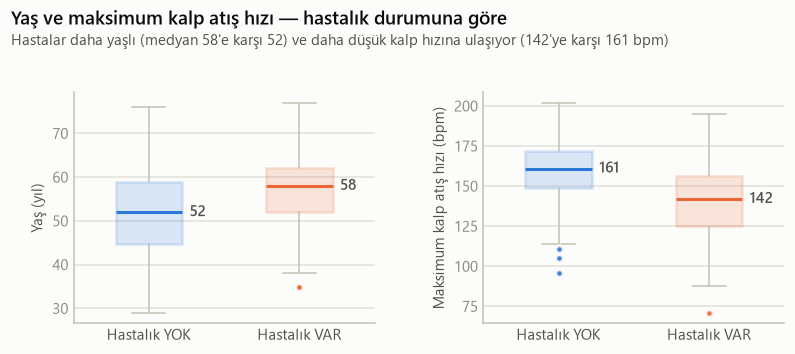

In [21]:
def kutu_ciz(ax, kolon, eksen_adi):
    gruplar = [df_temiz.loc[df_temiz["target"] == s, kolon].values for s in (0, 1)]
    bp = ax.boxplot(gruplar, widths=0.44, patch_artist=True, showfliers=True,
                    whiskerprops=dict(color=AXIS, linewidth=1.0),
                    capprops=dict(color=AXIS, linewidth=1.0))
    for kutu, renk in zip(bp["boxes"], (C_YOK, C_VAR)):
        kutu.set(facecolor=renk, alpha=0.16, edgecolor=renk, linewidth=1.8)
    for orta, renk in zip(bp["medians"], (C_YOK, C_VAR)):
        orta.set(color=renk, linewidth=2.0)
    for ucuk, renk in zip(bp["fliers"], (C_YOK, C_VAR)):
        ucuk.set(marker="o", markersize=5, markerfacecolor=renk,
                 markeredgecolor=SURFACE, markeredgewidth=2.0, alpha=0.9)

    # Medyanları doğrudan etiketle (seçici etiketleme: kıyaslamanın özü bu iki sayı)
    for i, s in enumerate((0, 1)):
        med = df_temiz.loc[df_temiz["target"] == s, kolon].median()
        ax.text(i + 1 + 0.27, med, f"{med:g}", va="center", ha="left",
                fontsize=10, color=INK_2, fontweight="semibold")

    ax.set_xticks([1, 2])
    ax.set_xticklabels(["Hastalık YOK", "Hastalık VAR"])
    ax.tick_params(axis="x", labelcolor=INK_2, labelsize=10)
    ax.set_ylabel(eksen_adi, fontsize=9.5, color=INK_2)
    ax.yaxis.grid(True, color=GRID, linewidth=1.0)
    ax.set_axisbelow(True)


print(df_temiz.groupby("target")[["age", "thalach"]]
      .agg(["median", "mean", "std"]).round(1))

fig = plt.figure(figsize=(7.6, 3.5), facecolor=SURFACE)
eksenler = []
for sol in (0.09, 0.58):
    ax = fig.add_axes([sol, 0.15, 0.36, 0.60])
    ax.set_facecolor(SURFACE)
    for yan in ("top", "right"):
        ax.spines[yan].set_visible(False)
    for yan in ("left", "bottom"):
        ax.spines[yan].set_color(AXIS)
        ax.spines[yan].set_linewidth(1.0)
    ax.tick_params(colors=MUTED, length=0, labelsize=9.5)
    eksenler.append(ax)

kutu_ciz(eksenler[0], "age", "Yaş (yıl)")
kutu_ciz(eksenler[1], "thalach", "Maksimum kalp atış hızı (bpm)")

baslik(fig,
       "Yaş ve maksimum kalp atış hızı — hastalık durumuna göre",
       "Hastalar daha yaşlı (medyan 58'e karşı 52) ve daha düşük kalp hızına ulaşıyor "
       "(142'ye karşı 161 bpm)")
kaydet(fig, "g3_yas_thalach_boxplot")
plt.show()

**Yorum.** İki panel birlikte okunduğunda hastalığın iki farklı izini gösteriyor:

- **Yaş:** hastalıklı grubun medyanı **58**, sağlıklı grubun **52**. Fark var ama kutular
  büyük ölçüde üst üste biniyor — yaş tek başına ayırıcı değil, zayıf bir eğilim
  (r = +0.22). Yaş bantlarına bakıldığında oran 40–50'de %30 iken 60–70'te %59'a çıkıyor.
- **Maksimum kalp atış hızı (`thalach`):** burada ayrışma çok daha net. Hastalıklı grubun
  medyanı **142 bpm**, sağlıklı grubun **161 bpm** — yani **19 bpm**'lik bir fark ve
  kutuların örtüşmesi belirgin biçimde daha az.

Sonuca etkisi: `thalach`, hedefle **negatif** yönde en güçlü korelasyona sahip sayısal
değişken (r = −0.42). Egzersizde yüksek kalp hızına ulaşabilmek koruyucu bir işaret;
düşük `thalach` ise hastalık lehine güçlü bir kanıt. Model için `age`'den daha değerli
bir özellik.

### Grafik 4 — Göğüs ağrısı tipine (cp) göre hastalık oranı

Göğüs ağrısı tipi                Toplam  Hasta   Oran
Atipik anjina (cp=2)                 50      9   %18.00
Anjina dışı ağrı (cp=3)              86     18   %20.93
Tipik anjina (cp=1)                  23      7   %30.43
Asemptomatik (cp=4)                 144    105   %72.92
Genel ortalama: %45.87


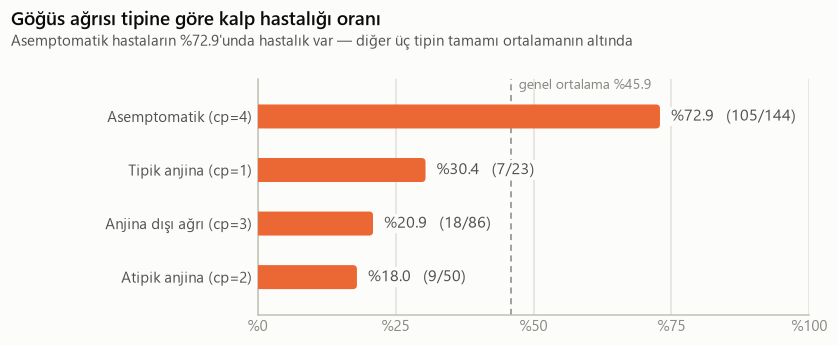

In [22]:
gogus = df_temiz.groupby("cp")["target"].agg(["size", "sum", "mean"])
gogus.index = [f"{CP_AD[int(k)]} (cp={int(k)})" for k in gogus.index]
gogus["oran_%"] = (gogus["mean"] * 100).round(2)
gogus = gogus.sort_values("mean")

print("Göğüs ağrısı tipi                Toplam  Hasta   Oran")
for ad, satir in gogus.iterrows():
    print(f"{ad:32s} {int(satir['size']):6d} {int(satir['sum']):6d}   %{satir['oran_%']:.2f}")
print(f"Genel ortalama: %{genel_oran:.2f}")

fig, ax = eksen(7.6, 3.4, sol=0.31, sag=0.97, alt=0.15, ust=0.78)
ax.set_xlim(0, 100)
ax.set_ylim(-0.7, len(gogus) - 0.3)
ax.xaxis.grid(True, color=GRID, linewidth=1.0)

for i, (ad, satir) in enumerate(gogus.iterrows()):
    cubuk_yatay(ax, i, satir["oran_%"], C_VAR)
    ax.text(satir["oran_%"] + 2.0, i,
            f"%{satir['oran_%']:.1f}   ({int(satir['sum'])}/{int(satir['size'])})",
            va="center", ha="left", fontsize=10.5, color=INK_2,
            bbox=dict(facecolor=SURFACE, edgecolor="none", pad=1.6))

ax.axvline(genel_oran, color=MUTED, linewidth=1.0, linestyle=(0, (4, 3)), zorder=2)
ax.text(genel_oran, len(gogus) - 0.42, f"  genel ortalama %{genel_oran:.1f}",
        ha="left", va="center", fontsize=9, color=MUTED)

ax.set_yticks(range(len(gogus)))
ax.set_yticklabels(gogus.index)
ax.tick_params(axis="y", labelcolor=INK_2, labelsize=10)
ax.set_xticks([0, 25, 50, 75, 100])
ax.set_xticklabels(["%0", "%25", "%50", "%75", "%100"])

baslik(fig,
       "Göğüs ağrısı tipine göre kalp hastalığı oranı",
       "Asemptomatik hastaların %72.9'unda hastalık var — diğer üç tipin tamamı "
       "ortalamanın altında")
kaydet(fig, "g4_gogus_agrisi_orani")
plt.show()

**Yorum.** Dört göğüs ağrısı tipi arasında çok keskin bir ayrışma var:

| Göğüs ağrısı tipi | Hastalık oranı |
|---|---|
| Asemptomatik (cp=4) | **%72.9** (105/144) |
| Tipik anjina (cp=1) | %30.4 (7/23) |
| Anjina dışı ağrı (cp=3) | %20.9 (18/86) |
| Atipik anjina (cp=2) | %18.0 (9/50) |

Sonuca etkisi: **`cp` tek başına güçlü bir ayırıcıdır.** Asemptomatik grup ortalamanın
27 puan üzerinde, diğer üç grup ise 15–28 puan altında; yani bu değişken hastaları
yüksek ve düşük riskli iki bloğa neredeyse tek hamlede ayırıyor.

İlk bakışta ters görünen nokta şudur: *göğüs ağrısı olmayan* hastalarda oran en yüksek.
Bunun nedeni veri setinin bir **klinik sevk popülasyonundan** gelmesidir — bu hastaların
tamamı bir nedenle teste yönlendirilmiş. Tipik anjina şikâyeti olanların önemli kısmında
daralma bulunmazken, tipik ağrı tarifi olmayan ileri yaştaki hastalarda hastalık sessiz
seyredip testte ortaya çıkmış. Bu, modelin öğrenebileceği gerçek bir örüntü; ancak
**genel popülasyona taşınamaz** (seçilim yanlılığı) ve raporlamada bu not edilmelidir.
Pratik sonuç: `cp` sayısal bırakılmamalı — 4 > 1 gibi bir sıralama yanlış olur, nitekim
en yüksek riskli grup kod 4, en düşük riskli grup kod 2'dir. One-Hot Encoding bu yüzden
gerekliydi.

### Grafik 5 — Korelasyon matrisi (heatmap)

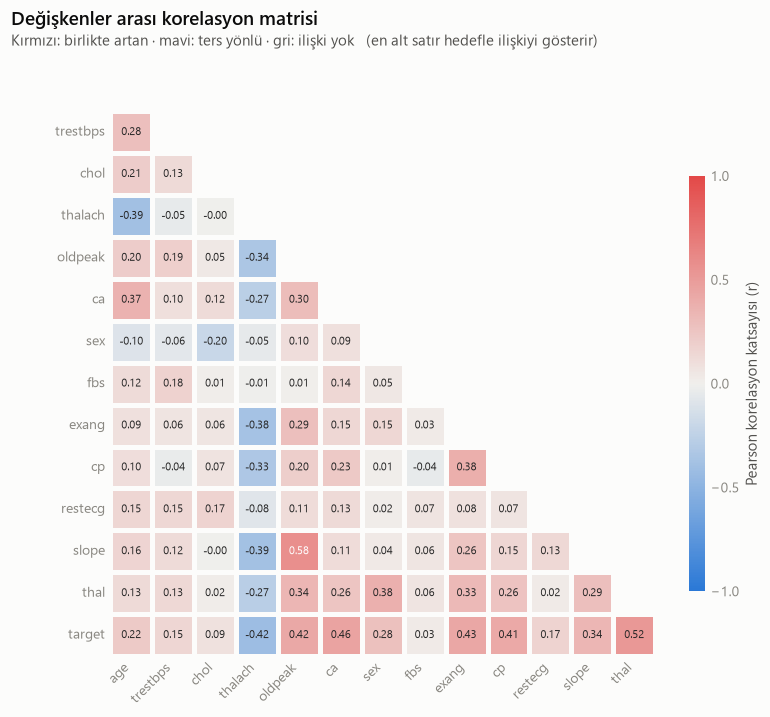

In [23]:
kor_kolonlar = SAYISAL + IKILI + KATEGORIK + ["target"]
kor = df_temiz[kor_kolonlar].astype(float).corr(method="pearson")

# Alt üçgen: üst üçgen aynı bilgiyi tekrarlar, köşegen her zaman 1.00
kor_alt = kor.iloc[1:, :-1]
maske = np.triu(np.ones_like(kor_alt, dtype=bool), k=1)

fig = plt.figure(figsize=(8.6, 6.9), facecolor=SURFACE)
ax = fig.add_axes([0.12, 0.11, 0.72, 0.76])
ax.set_facecolor(SURFACE)

sns.heatmap(
    kor_alt, mask=maske, cmap=CMAP_DIV, vmin=-1, vmax=1, center=0,
    annot=True, fmt=".2f", annot_kws={"fontsize": 7.4},
    linewidths=2, linecolor=SURFACE, square=True, ax=ax,
    cbar_kws={"shrink": 0.72, "aspect": 26, "ticks": [-1, -0.5, 0, 0.5, 1],
              "label": "Pearson korelasyon katsayısı (r)"},
)

ax.tick_params(colors=MUTED, length=0, labelsize=9)
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
plt.setp(ax.get_yticklabels(), rotation=0)

cbar = ax.collections[0].colorbar
cbar.outline.set_visible(False)
cbar.ax.tick_params(colors=MUTED, length=0, labelsize=9)
cbar.set_label("Pearson korelasyon katsayısı (r)", color=INK_2, fontsize=9.5)

baslik(fig,
       "Değişkenler arası korelasyon matrisi",
       "Kırmızı: birlikte artan · mavi: ters yönlü · gri: ilişki yok   "
       "(en alt satır hedefle ilişkiyi gösterir)")
kaydet(fig, "g5_korelasyon_matrisi")
plt.show()

**Yorum.** Matrisin **en alt satırı** (`target`) doğrudan "hangi değişken hastalığı ne
kadar açıklıyor" sorusunu yanıtlıyor:

- **Hedefle en güçlü ilişkiler:** `thal` (+0.52), `ca` (+0.46), `exang` (+0.43),
  `oldpeak` (+0.43), `cp` (+0.41) ve ters yönde `thalach` (−0.42). Bu altı değişken
  modelin taşıyıcı sütunları olacak.
- **Beklenenin aksine zayıf olanlar:** `chol` (+0.09) ve `fbs` (+0.03). Kolesterol ve
  açlık kan şekeri, klinik sezginin aksine bu veri setinde hedefle neredeyse ilişkisiz;
  yani modele tek başlarına çok az katkı sunacaklar. (Bu, kolesterolün önemsiz olduğu
  anlamına gelmez — bu hasta grubunun zaten çoğunlukla yüksek kolesterollü olması
  değişkenin ayırt etme gücünü düşürüyor.)
- **Değişkenler arası (çoklu doğrusallık) uyarısı:** en güçlü çift `oldpeak` ↔ `slope`
  (+0.58); ardından `age` ↔ `thalach` (−0.39), `thalach` ↔ `slope` (−0.39),
  `exang` ↔ `cp` (+0.38). Bu çiftler benzer bilgiyi taşıyor. Lojistik regresyonda
  katsayıların yorumunu bozabilir (ağaç tabanlı modeller için sorun değil).

**Önemli metodolojik not:** `cp`, `thal`, `restecg` ve `slope` **kategorik kodlardır**.
Pearson korelasyonu bunlar için yalnızca kabaca yön gösterir; kodların sırası anlamlı
olmadığından buradaki r değerleri gerçek ilişki gücünü eksik ölçebilir. Gerçek etkileri
Grafik 4'teki gibi grup oranlarıyla veya modelin özellik önemleriyle değerlendirmek gerekir.

### Grafik 6 — Hedefle korelasyonun sıralı özeti

Değişkenin hedefle korelasyonu (sıralı):
  Maks. kalp atış hızı       r = -0.417
  Açlık kan şekeri >120      r = +0.025
  Kolesterol                 r = +0.085
  Dinlenme kan basıncı       r = +0.151
  Dinlenme EKG               r = +0.169
  Yaş                        r = +0.223
  Cinsiyet (1=erkek)         r = +0.277
  ST eğimi                   r = +0.339
  Göğüs ağrısı tipi          r = +0.414
  ST çökmesi (oldpeak)       r = +0.425
  Egzersiz anjinası          r = +0.432
  Boyanan damar sayısı       r = +0.460
  Talyum testi               r = +0.522


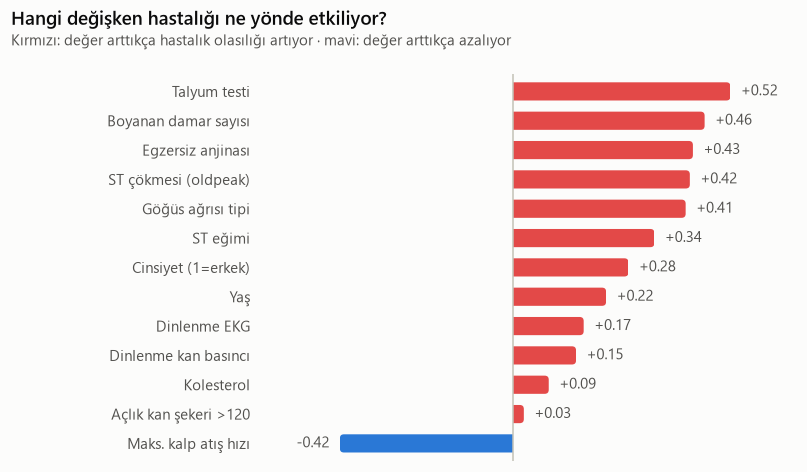

In [24]:
hedef_kor = kor["target"].drop("target").sort_values()

print("Değişkenin hedefle korelasyonu (sıralı):")
for kolon, r in hedef_kor.items():
    print(f"  {AD[kolon]:26s} r = {r:+.3f}")

fig, ax = eksen(7.8, 4.4, sol=0.30, sag=0.93, alt=0.04, ust=0.84)
ax.set_xlim(-0.62, 0.68)
ax.set_ylim(-0.6, len(hedef_kor) - 0.4)

for i, (kolon, r) in enumerate(hedef_kor.items()):
    cubuk_yatay(ax, i, r, DIV_POS if r > 0 else DIV_NEG, taban=0.0)
    kayma = 0.025 if r > 0 else -0.025
    ax.text(r + kayma, i, f"{r:+.2f}", va="center",
            ha="left" if r > 0 else "right", fontsize=10, color=INK_2)

ax.axvline(0, color=AXIS, linewidth=1.0, zorder=4)
ax.set_yticks(range(len(hedef_kor)))
ax.set_yticklabels([AD[k] for k in hedef_kor.index])
ax.tick_params(axis="y", labelcolor=INK_2, labelsize=10)
ax.set_xticks([])
ax.spines["bottom"].set_visible(False)
ax.spines["left"].set_visible(False)

baslik(fig,
       "Hangi değişken hastalığı ne yönde etkiliyor?",
       "Kırmızı: değer arttıkça hastalık olasılığı artıyor · "
       "mavi: değer arttıkça azalıyor")
kaydet(fig, "g6_hedef_korelasyon")
plt.show()

**Yorum.** Bu grafik beş grafiğin bulgusunu tek ölçekte topluyor; sıfır çizgisinden
uzaklık etkinin gücünü, yön ise etkinin işaretini veriyor.

- **Sağ uç (riski artıranlar):** `thal` talyum testi (+0.52), boyanan damar sayısı `ca`
  (+0.46), egzersiz anjinası `exang` (+0.43), ST çökmesi `oldpeak` (+0.43), göğüs ağrısı
  tipi `cp` (+0.41). Bunların hepsi **egzersiz/görüntüleme testi** sonuçları — yani
  hastalığın en güçlü habercileri demografik bilgi değil, kardiyak test bulguları.
- **Sol uç (koruyucu):** tek anlamlı negatif değişken `thalach` (−0.42). Yüksek maksimum
  kalp hızına ulaşabilmek hastalık olasılığını düşürüyor.
- **Ortadaki gri bölge:** `fbs` (+0.03), `chol` (+0.09), `trestbps` (+0.15) sıfıra çok
  yakın. Bu üçü modele neredeyse hiçbir ayırt edici bilgi katmayacak; özellik seçimi
  yapılacaksa ilk çıkarılacak adaylar bunlardır.

**Modellemeye etkisi:** hedefe dair sinyalin büyük kısmı 6 değişkende toplanmış
(`thal`, `ca`, `exang`, `oldpeak`, `cp`, `thalach`). Bu, 22 özellikli küçük bir veri
setinde (303 satır) basit modellerin — lojistik regresyon, az derinlikli karar
ağaçları — karmaşık modellerle yarışabileceğini, hatta aşırı öğrenmeye (*overfitting*)
daha dirençli olacağını gösteriyor. Ayrıca korelasyonun bir **doğrusal** ölçü olduğunu
hatırda tutmak gerekir: sıfıra yakın bir r, doğrusal olmayan bir ilişkiyi gizleyebilir,
bu yüzden özellikleri yalnızca bu grafiğe bakarak silmek yerine model başarımıyla
sınamak doğru olur.

## 8. Modelleme

Hazırladığımız veriyle üç sınıflandırma modeli kurup karşılaştıracağız:

1. **Logistic Regression** — doğrusal, yorumlanabilir temel model (*baseline*)
2. **Decision Tree** — doğrusal olmayan ilişkileri yakalayabilen tek karar ağacı
3. **Random Forest** — çok sayıda ağacın oyladığı topluluk (*ensemble*) modeli

Tüm modellerde `random_state=42` kullanıldı; sonuçlar tekrar çalıştırıldığında aynı çıkar.

> **Ortam notu:** Bu notebook `scikit-learn 1.7.2` ile çalışıyor. Daha yeni bir sürüme
> yükseltirseniz (`pip install -U scikit-learn`) Windows Smart App Control, imzasız olan
> `sklearn/tree/_tree.pyd` dosyasını engelleyebilir ve `DecisionTree` / `RandomForest`
> içe aktarılamaz. Böyle bir hata görürseniz `pip install scikit-learn==1.7.2` ile geri dönün.

In [25]:
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score,
                             precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

import sklearn
print("scikit-learn sürümü:", sklearn.__version__)

scikit-learn sürümü: 1.7.2


### 8.1 Train / Test ayrımı

Veriyi **%80 eğitim / %20 test** olarak bölüyoruz. İki ayrıntı önemli:

- **`stratify=y`**: sınıf oranı (%54 / %46) hem eğitim hem test kümesinde korunur.
  303 satırlık küçük bir veri setinde rastgele bölme, test kümesinin sınıf dengesini
  kolayca bozabilirdi.
- **`random_state=42`**: bölme her çalıştırmada aynı olur, sonuçlar tekrarlanabilir.

In [26]:
# X ve y, 5. bölümde hazırlanmıştı (One-Hot Encoding uygulanmış 22 özellik)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("Eğitim kümesi :", X_train.shape[0], "hasta,", X_train.shape[1], "özellik")
print("Test kümesi   :", X_test.shape[0], "hasta,", X_test.shape[1], "özellik")
print()
print("Sınıf dağılımı korundu mu?")
for ad, hedef in [("Tüm veri", y), ("Eğitim", y_train), ("Test", y_test)]:
    d = hedef.value_counts().sort_index()
    pay = hedef.mean() * 100
    print(f"  {ad:9s}: {d.get(0, 0):3d} sağlıklı / {d.get(1, 0):3d} hasta   (hasta oranı %{pay:.1f})")

Eğitim kümesi : 242 hasta, 22 özellik
Test kümesi   : 61 hasta, 22 özellik

Sınıf dağılımı korundu mu?
  Tüm veri : 164 sağlıklı / 139 hasta   (hasta oranı %45.9)
  Eğitim   : 131 sağlıklı / 111 hasta   (hasta oranı %45.9)
  Test     :  33 sağlıklı /  28 hasta   (hasta oranı %45.9)


### 8.2 Modellerin kurulması

**Neden Logistic Regression bir `Pipeline` içinde?** Lojistik regresyon, değişkenlerin
ölçeğine duyarlıdır: `chol` 126–564 arasında değişirken `oldpeak` 0–6.2 arasındadır,
ölçeklenmezse büyük sayılı değişken katsayıları domine eder. `StandardScaler` bunu
düzeltir. **Yalnızca sürekli değişkenler** ölçeklenir — One-Hot sütunları zaten 0/1'dir
ve ölçeklemek onları yorumlanamaz hale getirir.

Ölçekleyiciyi `Pipeline` içine koymak, ölçeğin **yalnızca eğitim verisinden** öğrenilmesini
garanti eder. Veri setinin tamamını önceden ölçeklemek, test kümesinin ortalama/standart
sapma bilgisini eğitime sızdırırdı (*data leakage*).

Karar ağaçları ve Random Forest ölçeklemeye ihtiyaç duymaz (eşik değerlerle bölme yapar),
bu yüzden onlar doğrudan kullanılıyor.

In [27]:
# Yalnızca sürekli sütunlar ölçeklenir; One-Hot ve ikili sütunlar olduğu gibi geçer
olcekleyici = ColumnTransformer(
    transformers=[("olcek", StandardScaler(), SAYISAL)],
    remainder="passthrough",
)

modeller = {
    "Logistic Regression": Pipeline([
        ("hazirlik", olcekleyici),
        ("model", LogisticRegression(max_iter=1000, random_state=42)),
    ]),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=42),
}

for ad, model in modeller.items():
    print(f"{ad:22s} -> {type(model).__name__}")

Logistic Regression    -> Pipeline
Decision Tree          -> DecisionTreeClassifier
Random Forest          -> RandomForestClassifier


### 8.3 Eğitim ve tahmin

Her model **yalnızca eğitim kümesiyle** öğreniyor, ardından **hiç görmediği** test
kümesi üzerinde tahmin yapıyor.

In [28]:
egitilmis = {}
tahminler = {}
olasiliklar = {}

for ad, model in modeller.items():
    model.fit(X_train, y_train)                        # eğitim
    egitilmis[ad] = model
    tahminler[ad] = model.predict(X_test)              # test tahmini (0/1)
    olasiliklar[ad] = model.predict_proba(X_test)[:, 1]  # hasta olma olasılığı
    print(f"{ad:22s} eğitildi ve {len(tahminler[ad])} test hastası için tahmin üretildi.")

Logistic Regression    eğitildi ve 61 test hastası için tahmin üretildi.
Decision Tree          eğitildi ve 61 test hastası için tahmin üretildi.


Random Forest          eğitildi ve 61 test hastası için tahmin üretildi.


### 8.4 Performans karşılaştırması

Metriklerin bu problemdeki anlamı:

| Metrik | Formül | Bu projede ne demek? |
|---|---|---|
| **Accuracy** | (TP+TN) / Toplam | Tüm hastaların yüzde kaçı doğru sınıflandırıldı |
| **Precision** | TP / (TP+FP) | "Hasta" dediklerimizin yüzde kaçı gerçekten hasta |
| **Recall** | TP / (TP+FN) | Gerçek hastaların yüzde kaçını yakalayabildik |

Tıbbi teşhiste **recall** önceliklidir: hasta birine "sağlıklı" demek (yanlış negatif),
sağlıklı birine "hasta" deyip ileri tetkike yollamaktan (yanlış pozitif) çok daha pahalı
bir hatadır.

Tabloya ayrıca üç yardımcı sütun eklendi: **F1** (precision ve recall'ın harmonik
ortalaması), **ROC-AUC** (modelin sıralama gücü) ve **Eğitim doğruluğu** (test
doğruluğuyla arasındaki fark aşırı öğrenmeyi gösterir).

In [29]:
satirlar = []
for ad in modeller:
    y_tahmin = tahminler[ad]
    satirlar.append({
        "Model": ad,
        "Accuracy": accuracy_score(y_test, y_tahmin),
        "Precision": precision_score(y_test, y_tahmin),
        "Recall": recall_score(y_test, y_tahmin),
        "F1": f1_score(y_test, y_tahmin),
        "ROC-AUC": roc_auc_score(y_test, olasiliklar[ad]),
        "Eğitim doğruluğu": accuracy_score(y_train, egitilmis[ad].predict(X_train)),
    })

sonuclar = pd.DataFrame(satirlar).set_index("Model")

cizgi = "=" * 86
print(cizgi)
print(f"{'Model':22s} {'Accuracy':>10s} {'Precision':>11s} {'Recall':>9s} "
      f"{'F1':>8s} {'ROC-AUC':>9s} {'Eğitim':>9s}")
print("-" * 86)
for ad, s in sonuclar.iterrows():
    print(f"{ad:22s} {s['Accuracy']*100:9.2f}% {s['Precision']*100:10.2f}% "
          f"{s['Recall']*100:8.2f}% {s['F1']*100:7.2f}% {s['ROC-AUC']*100:8.2f}% "
          f"{s['Eğitim doğruluğu']*100:8.2f}%")
print(cizgi)
print(f"Test kümesi: {len(y_test)} hasta ({int((y_test == 0).sum())} sağlıklı, "
      f"{int((y_test == 1).sum())} hasta)")

sonuclar.round(4)

Model                    Accuracy   Precision    Recall       F1   ROC-AUC    Eğitim
--------------------------------------------------------------------------------------
Logistic Regression        86.89%      81.25%    92.86%   86.67%    95.78%    85.95%
Decision Tree              78.69%      71.43%    89.29%   79.37%    79.49%   100.00%
Random Forest              86.89%      81.25%    92.86%   86.67%    94.75%   100.00%
Test kümesi: 61 hasta (33 sağlıklı, 28 hasta)


,Accuracy,Precision,Recall,F1,ROC-AUC,Eğitim doğruluğu
Model,,,,,,
Logistic Regression,0.8689,0.8125,0.9286,0.8667,0.9578,0.8595
Decision Tree,0.7869,0.7143,0.8929,0.7937,0.7949,1.0000
Random Forest,0.8689,0.8125,0.9286,0.8667,0.9475,1.0000


**Yorum — test sonuçları.**

| Model | Accuracy | Precision | Recall |
|---|---|---|---|
| Logistic Regression | **%86.89** | **%81.25** | **%92.86** |
| Decision Tree | %78.69 | %71.43 | %89.29 |
| Random Forest | **%86.89** | **%81.25** | **%92.86** |

- **Logistic Regression ve Random Forest bu test kümesinde birebir aynı sonucu verdi.**
  Bu bir hata değil; 61 kişilik test kümesinde iki model aynı 8 hastada yanılmış. Küçük
  test kümelerinde bu tür eşitlikler olağandır — tek bir hasta %1.6 puan değiştirir.
  Bu yüzden iki modeli ayırmak için 8.6'daki çapraz doğrulamaya bakacağız.
- **Decision Tree açık ara sonuncu** (%78.69). Nedeni eğitim doğruluğu sütununda:
  **%100**. Ağaç eğitim verisini ezberlemiş (*overfitting*), yeni hastalara
  genelleyememiş. Tek bir ağaç, derinliği sınırlanmadığında 242 satırlık bir veride
  neredeyse her zaman ezberler.
- **Random Forest'ın eğitim doğruluğu da %100** ama test başarımı yüksek. Bu normaldir:
  her ağaç ezberler, fakat 300 ağacın oyu ezberin rastgele kısmını birbirini götürerek
  temizler. Topluluk modellerinin varlık nedeni tam olarak budur.
- **Recall her üç modelde de precision'dan yüksek** (%89–93 ve %71–81). Yani modeller
  hastaları kaçırmaktan çok, sağlıklıya "hasta" demeye meyilli. Tıbbi tarama açısından
  **istenen yön budur**.
- **ROC-AUC**'ta Logistic Regression (%95.78) Random Forest'ın (%94.75) hafif önünde:
  eşik 0.5'te aynı kararları verseler de lojistik regresyon hastaları olasılığa göre
  biraz daha iyi sıralıyor.

### 8.5 Karmaşıklık matrisleri (hataların dökümü)

Metrik yüzdeleri hangi hatadan geldiğini göstermez. Asıl soru şu: kaç hastayı kaçırdık?

In [30]:
for ad in modeller:
    tn, fp, fn, tp = confusion_matrix(y_test, tahminler[ad]).ravel()
    print(f"--- {ad} ---")
    print(f"  Doğru negatif  (sağlıklı, doğru bilindi)  : {tn:3d}")
    print(f"  Yanlış pozitif (sağlıklı, 'hasta' dendi)  : {fp:3d}   <- gereksiz tetkik")
    print(f"  Yanlış negatif (hasta, KAÇIRILDI)         : {fn:3d}   <- tehlikeli hata")
    print(f"  Doğru pozitif  (hasta, yakalandı)         : {tp:3d}")
    print(f"  Toplam hata: {fp + fn} / {len(y_test)}")
    print()

--- Logistic Regression ---
  Doğru negatif  (sağlıklı, doğru bilindi)  :  27
  Yanlış pozitif (sağlıklı, 'hasta' dendi)  :   6   <- gereksiz tetkik
  Yanlış negatif (hasta, KAÇIRILDI)         :   2   <- tehlikeli hata
  Doğru pozitif  (hasta, yakalandı)         :  26
  Toplam hata: 8 / 61

--- Decision Tree ---
  Doğru negatif  (sağlıklı, doğru bilindi)  :  23
  Yanlış pozitif (sağlıklı, 'hasta' dendi)  :  10   <- gereksiz tetkik
  Yanlış negatif (hasta, KAÇIRILDI)         :   3   <- tehlikeli hata
  Doğru pozitif  (hasta, yakalandı)         :  25
  Toplam hata: 13 / 61

--- Random Forest ---
  Doğru negatif  (sağlıklı, doğru bilindi)  :  27
  Yanlış pozitif (sağlıklı, 'hasta' dendi)  :   6   <- gereksiz tetkik
  Yanlış negatif (hasta, KAÇIRILDI)         :   2   <- tehlikeli hata
  Doğru pozitif  (hasta, yakalandı)         :  26
  Toplam hata: 8 / 61



**Yorum — hataların niteliği.** Logistic Regression ve Random Forest, 28 hastanın
**26'sını yakalayıp yalnızca 2'sini kaçırdı**; buna karşılık 33 sağlıklı kişinin 6'sına
gereksiz yere "hasta" dedi. Decision Tree ise 3 hasta kaçırdı ve 10 yanlış alarm üretti.

Bu dağılım klinik açıdan doğru taraftadır: **yanlış negatif sayısı düşük**. Gerçek bir
tarama senaryosunda yanlış pozitifin bedeli ek bir efor testi veya anjiyografi iken,
yanlış negatifin bedeli tedavi edilmemiş bir kalp hastasıdır. Recall'ı daha da yükseltmek
isterseniz karar eşiğini 0.5'ten (örneğin) 0.35'e çekmek mümkündür — bu, daha fazla yanlış
pozitif karşılığında daha az kaçırılan hasta demektir.

### 8.6 Çapraz doğrulama — sonuç tek bir bölmeye mi bağlı?

Test kümesi yalnızca **61 hasta**. Bu kadar küçük bir kümede tek bir hastanın farklı
sınıflanması sonucu %1.6 puan oynatır; dolayısıyla "Logistic Regression ve Random Forest
eşit" sonucu, seçtiğimiz bölmeye özgü bir tesadüf olabilir.

**5 katlı çapraz doğrulama** bu riski ortadan kaldırır: veri 5 parçaya bölünür, her tur
farklı bir parça test olur ve **her hasta tam bir kez test edilir**. Elde edilen ortalama
ve standart sapma, tek bir bölmeden çok daha güvenilirdir.

In [31]:
kat = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_satirlar = []
for ad, model in modeller.items():
    skor = cross_validate(model, X, y, cv=kat,
                          scoring=["accuracy", "precision", "recall"])
    cv_satirlar.append({
        "Model": ad,
        "Accuracy": skor["test_accuracy"].mean(),
        "Acc ± std": skor["test_accuracy"].std(),
        "Precision": skor["test_precision"].mean(),
        "Recall": skor["test_recall"].mean(),
        "Recall ± std": skor["test_recall"].std(),
    })

cv_sonuclar = pd.DataFrame(cv_satirlar).set_index("Model")

print("5 KATLI ÇAPRAZ DOĞRULAMA (303 hastanın tamamı üzerinde)")
print("=" * 72)
print(f"{'Model':22s} {'Accuracy':>16s} {'Precision':>11s} {'Recall':>16s}")
print("-" * 72)
for ad, s in cv_sonuclar.iterrows():
    print(f"{ad:22s} {s['Accuracy']*100:8.2f}% ± {s['Acc ± std']*100:4.2f} "
          f"{s['Precision']*100:10.2f}% {s['Recall']*100:9.2f}% ± {s['Recall ± std']*100:4.2f}")
print("=" * 72)

cv_sonuclar.round(4)

5 KATLI ÇAPRAZ DOĞRULAMA (303 hastanın tamamı üzerinde)
Model                          Accuracy   Precision           Recall
------------------------------------------------------------------------
Logistic Regression       84.81% ± 3.84      86.81%     79.10% ± 3.74
Decision Tree             77.19% ± 6.10      75.73%     74.76% ± 4.35
Random Forest             82.51% ± 2.18      84.43%     76.27% ± 2.75


,Accuracy,Acc ± std,Precision,Recall,Recall ± std
Model,,,,,
Logistic Regression,0.8481,0.0384,0.8681,0.7910,0.0374
Decision Tree,0.7719,0.0610,0.7573,0.7476,0.0435
Random Forest,0.8251,0.0218,0.8443,0.7627,0.0275


**Yorum — çapraz doğrulama tabloyu değiştiriyor.**

| Model | CV Accuracy | CV Precision | CV Recall |
|---|---|---|---|
| Logistic Regression | **%84.81 ± 3.84** | **%86.81** | **%79.10 ± 3.74** |
| Decision Tree | %77.19 ± 6.10 | %75.73 | %74.76 ± 4.35 |
| Random Forest | %82.51 ± 2.18 | %84.43 | %76.27 ± 2.75 |

Tek bölmede eşit görünen iki model burada ayrışıyor: **Logistic Regression üç metrikte de
Random Forest'ın önünde** (accuracy'de 2.3, recall'da 2.8 puan). Ayrıca dikkat edilmesi
gereken iki nokta var:

- **Çapraz doğrulama skorları test skorlarından düşük** (recall %79'a karşı %93). Yani
  8.4'teki test kümesi şanslı bir bölmeymiş. Projeyi raporlarken dürüst rakam bu
  tablodakidir; tek bölmenin sonucu iyimser bir tahmindir.
- **Decision Tree'nin standart sapması en yüksek** (±6.10). Tek ağaç yalnızca başarısız
  değil, aynı zamanda **kararsız**: hangi veriyle eğitildiğine göre sonucu belirgin
  şekilde değişiyor. Random Forest'ın ±2.18'lik sapması, 300 ağacın oylamasının bu
  oynaklığı nasıl söndürdüğünü gösteriyor.

### Sonuç: hangi modeli seçmeli?

**Logistic Regression.** Gerekçeler:

1. Çapraz doğrulamada **en yüksek** accuracy, precision ve recall değerlerine sahip.
2. **Aşırı öğrenme yok** — eğitim (%85.95) ve test (%86.89) doğrulukları birbirine yakın;
   diğer iki model eğitimde %100 yapıyor.
3. **Yorumlanabilir**: her değişkenin katsayısı, hastalık olasılığını hangi yönde ve ne
   kadar etkilediğini doğrudan söyler. Tıbbi bir karar destek aracında bu şeffaflık,
   birkaç puanlık başarımdan daha değerlidir.
4. 303 satırlık küçük bir veri setinde basit modelin kazanması beklenen bir sonuçtur —
   Grafik 6'da sinyalin 6 değişkende toplandığını zaten görmüştük; bu yapıyı yakalamak
   için karmaşık bir modele gerek yok.

Decision Tree'yi kullanmak isterseniz tek başına değil, **derinliği sınırlandırılmış**
olarak (`max_depth=3-4`) kullanılmalı; mevcut haliyle ezberlediği için en zayıf model.

## 9. En iyi model: seçim, hata analizi ve yorum

Bu bölümde en iyi modeli seçip hatalarını mikroskop altına alıyoruz:

- **9.1** Karmaşıklık matrisi görselleştirmesi
- **9.2** *Yanlış negatif mi, yanlış pozitif mi daha kötü?* — tıbbi açıdan cevap
- **9.3** Modelin yanıldığı 3 hastanın tek tek incelenmesi (bonus)

### Model seçimi

Seçimi **test kümesine göre değil, çapraz doğrulamaya göre** yapıyoruz. Nedeni 8.6'da
görülmüştü: test kümesinde Logistic Regression ve Random Forest birebir aynı sonucu
vermişti (61 hastalık bir küme iki modeli ayırmaya yetmiyor). Çapraz doğrulama 303
hastanın tamamını kullandığı için daha güvenilir bir ölçüdür.

In [32]:
EN_IYI = cv_sonuclar["Accuracy"].idxmax()

print("Çapraz doğrulama accuracy sıralaması:")
for ad, s in cv_sonuclar.sort_values("Accuracy", ascending=False).iterrows():
    isaret = "  <-- SEÇİLDİ" if ad == EN_IYI else ""
    print(f"  {ad:22s} %{s['Accuracy']*100:.2f} ± {s['Acc ± std']*100:.2f}{isaret}")

print()
print(f"Seçilen model: {EN_IYI}")
print(f"  Test accuracy  : %{sonuclar.loc[EN_IYI, 'Accuracy']*100:.2f}")
print(f"  Test precision : %{sonuclar.loc[EN_IYI, 'Precision']*100:.2f}")
print(f"  Test recall    : %{sonuclar.loc[EN_IYI, 'Recall']*100:.2f}")
print(f"  Eğitim doğruluğu: %{sonuclar.loc[EN_IYI, 'Eğitim doğruluğu']*100:.2f} "
      f"(test ile farkı küçük -> aşırı öğrenme yok)")

en_iyi_model = egitilmis[EN_IYI]

Çapraz doğrulama accuracy sıralaması:
  Logistic Regression    %84.81 ± 3.84  <-- SEÇİLDİ
  Random Forest          %82.51 ± 2.18
  Decision Tree          %77.19 ± 6.10

Seçilen model: Logistic Regression
  Test accuracy  : %86.89
  Test precision : %81.25
  Test recall    : %92.86
  Eğitim doğruluğu: %85.95 (test ile farkı küçük -> aşırı öğrenme yok)


### 9.1 Karmaşıklık matrisi görselleştirmesi

Matrisin okunuşu: **satırlar gerçek durumu**, **sütunlar modelin tahminini** gösterir.
Köşegen (sol üst ve sağ alt) doğru tahminler, köşegen dışı iki hücre ise iki farklı
hata türüdür. Renk yoğunluğu hasta sayısıyla orantılıdır; sayılar her hücrede yazılı
olduğu için hiçbir değer yalnızca renge bağlı değildir.

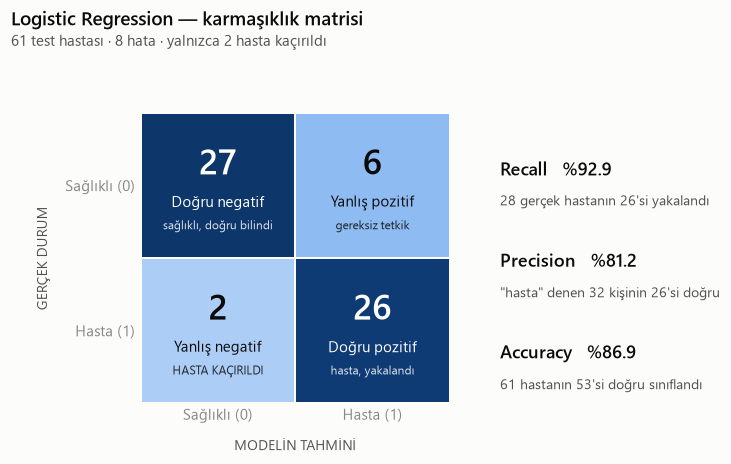

In [33]:
km = confusion_matrix(y_test, tahminler[EN_IYI])
tn, fp, fn, tp = km.ravel()

# Sıralı (sequential) tek renk skalası: açıktan koyuya, büyüklüğü kodlar
CMAP_SIRALI = LinearSegmentedColormap.from_list(
    "mavi_sirali",
    ["#b7d3f6", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"],
)

hucre_ad = [["Doğru negatif", "Yanlış pozitif"],
            ["Yanlış negatif", "Doğru pozitif"]]
hucre_not = [["sağlıklı, doğru bilindi", "gereksiz tetkik"],
             ["HASTA KAÇIRILDI", "hasta, yakalandı"]]

fig = plt.figure(figsize=(7.6, 4.4), facecolor=SURFACE)
ax = fig.add_axes([0.17, 0.16, 0.37, 0.60])
ax.set_facecolor(SURFACE)
ax.set_xlim(0, 2)
ax.set_ylim(2, 0)                      # satır 0 üstte
for yan in ("top", "right", "left", "bottom"):
    ax.spines[yan].set_visible(False)

dx, dy = _px_birim(ax)
gx, gy = 1.0 * dx, 1.0 * dy            # her kenarda 1px -> hücreler arası 2px boşluk
en_buyuk = km.max()

for i in range(2):
    for j in range(2):
        deger = int(km[i, j])
        oran = deger / en_buyuk
        ax.add_patch(Rectangle((j + gx, i + gy), 1 - 2 * gx, 1 - 2 * gy,
                               facecolor=CMAP_SIRALI(oran), linewidth=0))
        yazi = "#ffffff" if oran > 0.55 else INK
        ax.text(j + 0.5, i + 0.36, str(deger), ha="center", va="center",
                fontsize=23, color=yazi, fontweight="semibold")
        ax.text(j + 0.5, i + 0.62, hucre_ad[i][j], ha="center", va="center",
                fontsize=9.5, color=yazi)
        ax.text(j + 0.5, i + 0.78, hucre_not[i][j], ha="center", va="center",
                fontsize=8, color=yazi, alpha=0.85)

ax.set_xticks([0.5, 1.5])
ax.set_xticklabels(["Sağlıklı (0)", "Hasta (1)"])
ax.set_yticks([0.5, 1.5])
ax.set_yticklabels(["Sağlıklı (0)", "Hasta (1)"])
ax.tick_params(colors=MUTED, length=0, labelsize=9.5)
ax.set_xlabel("MODELİN TAHMİNİ", fontsize=9, color=INK_2, labelpad=10)
ax.set_ylabel("GERÇEK DURUM", fontsize=9, color=INK_2, labelpad=10)

# Sağ taraftaki okuma kılavuzu
satirlar_metin = [
    ("Recall", f"%{sonuclar.loc[EN_IYI, 'Recall']*100:.1f}",
     f"{tp + fn} gerçek hastanın {tp}'si yakalandı"),
    ("Precision", f"%{sonuclar.loc[EN_IYI, 'Precision']*100:.1f}",
     f"\"hasta\" denen {tp + fp} kişinin {tp}'si doğru"),
    ("Accuracy", f"%{sonuclar.loc[EN_IYI, 'Accuracy']*100:.1f}",
     f"{len(y_test)} hastanın {tn + tp}'si doğru sınıflandı"),
]
y_imlec = 0.66
for etiket, deger, aciklama in satirlar_metin:
    fig.text(0.60, y_imlec, f"{etiket}   {deger}", fontsize=11.5, color=INK,
             fontweight="semibold", va="top")
    fig.text(0.60, y_imlec - 0.07, aciklama, fontsize=9, color=INK_2, va="top")
    y_imlec -= 0.19

baslik(fig, f"{EN_IYI} — karmaşıklık matrisi",
       f"{len(y_test)} test hastası · {fp + fn} hata · yalnızca {fn} hasta kaçırıldı")
kaydet(fig, "g7_karmasiklik_matrisi")
plt.show()

**Yorum.** Matris, %86.89'luk doğruluğun nereden geldiğini açıyor:

- **Köşegen (27 + 26 = 53 hasta)** doğru sınıflandırıldı.
- **6 yanlış pozitif:** sağlıklı oldukları halde "hasta" denen kişiler. Bedeli bir ileri
  tetkik.
- **2 yanlış negatif:** gerçekten hasta oldukları halde "sağlıklı" denen kişiler. Asıl
  tehlikeli hücre burasıdır ve modelin en iyi yanı bu hücrenin küçük olmasıdır.

Hataların dağılımı dengeli değil ve bu **kasıtlı olarak istenen** yöndedir: model
emin olmadığında "hasta" demeye meyilli. Bir sonraki bölümde bunun neden doğru tasarım
tercihi olduğunu açıklıyoruz.

### 9.2 Hangisi daha kötü: yanlış negatif mi, yanlış pozitif mi?

> **Soru:** Bu kalp hastalığı probleminde "yanlış hayır" (False Negative) demek mi daha
> kötü, "yanlış evet" (False Positive) demek mi? Neden?

**Cevap: Yanlış negatif (FN) kıyaslanamayacak kadar daha kötüdür.**

#### İki hatanın tıbbi karşılığı

| | **Yanlış negatif (FN)** | **Yanlış pozitif (FP)** |
|---|---|---|
| **Ne oldu?** | Kalp hastası olan kişiye "sağlıklısın" dendi | Sağlıklı kişiye "hasta olabilirsin" dendi |
| **Hastaya ne olur?** | Eve gönderilir, tedavi başlamaz, takibe alınmaz | İleri tetkike yönlendirilir (efor testi, anjiyografi) |
| **Sonucu** | Tedavi edilmemiş koroner arter hastalığı: miyokart enfarktüsü, kalp yetmezliği, ani kardiyak ölüm | Kaygı, zaman ve para kaybı, invaziv işlem riski |
| **Geri dönüşü var mı?** | **Yok.** Kalp krizi geçiren hastada oluşan doku hasarı kalıcıdır | **Var.** İleri tetkik hatayı ortaya çıkarır ve hasta "temiz" raporla ayrılır |

#### Asıl gerekçe: hatanın geri döndürülebilirliği

İki hata da maliyetlidir, ancak **maliyetleri aynı türden değildir**:

- **Yanlış pozitifin maliyeti bir sonraki adımda düzeltilir.** Sağlıklı birine "hasta
  olabilir" dediğinizde, o kişi anjiyografiye gider ve damarlarının temiz olduğu
  görülür. Sistem kendi hatasını yakalar. Bedeli; gereksiz tetkik masrafı, hastanın
  birkaç günlük kaygısı ve küçük de olsa işleme bağlı komplikasyon riskidir.
- **Yanlış negatifin maliyetini düzeltecek bir sonraki adım yoktur.** Hasta birine
  "sağlıklısın" dediğinizde o kişi sistemden çıkar. Hatanın ortaya çıkması, çoğu zaman
  hastanın acil servise kalp kriziyle gelmesiyle olur. O noktada kaybedilen kalp kası
  geri gelmez.

Bu yüzden tarama araçlarında (*screening*) standart yaklaşım **yüksek duyarlılıktır**
(*sensitivity* = recall). Bir tarama modeli **teşhis koymaz**, yalnızca "bu kişiye daha
yakından bakılsın" der. Kesin teşhisi anjiyografi koyar. Dolayısıyla modelin işi
şüphelileri elemek değil, **şüphelileri kaçırmamaktır**.

#### Bu projedeki sayısal karşılığı

Modelimiz 28 gerçek hastanın **26'sını yakaladı, 2'sini kaçırdı** (recall %92.86) ve
bunun karşılığında 6 sağlıklı kişiye gereksiz yere "hasta" dedi (precision %81.25).
Bu takas **bilinçli olarak doğru taraftadır**: 6 kişinin ek tetkike gitmesi, 2 yerine
1 hastanın kaçırılmasından iyidir.

Recall'ı daha da yükseltmek isterseniz karar eşiğini 0.50'den örneğin 0.35'e
çekebilirsiniz; model daha çok kişiye "hasta" der, yanlış negatif sayısı düşer,
yanlış pozitif sayısı artar.

#### Ama "herkese hasta de" neden çözüm değil?

Eşiği sıfıra çekerseniz recall %100 olur — hiç hasta kaçırmazsınız. Ancak o noktada
precision %45.9'a (veri setindeki hasta oranına) düşer ve model **hiçbir bilgi
üretmemiş** olur; herkesi anjiyografiye yollayan bir araca kimse ihtiyaç duymaz.
Dahası, gereksiz invaziv işlemler gerçek zarar verir ve aşırı yanlış alarm, klinisyenin
uyarıları ciddiye almayı bırakmasına yol açar (*alarm yorgunluğu*).

Dolayısıyla doğru hedef "FN'i sıfırlamak" değil, **FN'e FP'den çok daha ağır bir ceza
vererek dengeyi kurmaktır.** Pratikte bunun yolları: karar eşiğini düşürmek,
`class_weight={0: 1, 1: 3}` gibi ağırlıklandırma kullanmak veya modeli F1 yerine
**F2 skoru** (recall'a precision'ın iki katı ağırlık verir) ile optimize etmektir.

### 9.3 Bonus — modelin yanıldığı 3 hastanın incelenmesi

Model test kümesinde 8 hata yaptı. İncelemek için şu 3'ünü seçiyoruz:

- **Her iki yanlış negatifi** (tehlikeli hata türü oldukları için ikisi de incelenmeli)
- **En yüksek olasılıkla yanıldığı yanlış pozitifi** (model %97.5 emin olduğu halde
  yanılmış — en öğretici vaka)

Lojistik regresyon doğrusal bir model olduğu için **her değişkenin karara katkısını tek
tek hesaplayabiliriz**: `katkı = katsayı × ölçeklenmiş değer`. Bu katkıların toplamı
artı sabit terim, modelin karar skorunu verir. Böylece "model neden yanıldı?" sorusunu
tahminle değil, sayıyla cevaplıyoruz.

In [34]:
# One-Hot öncesi okunabilir değerler + modelin tahmini
test_ham = df_temiz.loc[X_test.index].copy()
yanlis_maske = y_test.values != tahminler[EN_IYI]

hatalilar = test_ham.loc[yanlis_maske, ["age", "sex", "cp", "trestbps", "chol",
                                        "thalach", "exang", "oldpeak", "slope",
                                        "ca", "thal", "target"]].copy()
hatalilar["olasilik"] = olasiliklar[EN_IYI][yanlis_maske].round(3)
hatalilar["hata_tipi"] = ["Yanlış negatif" if g == 1 else "Yanlış pozitif"
                          for g in hatalilar["target"]]

print(f"{EN_IYI} modelinin {len(hatalilar)} hatası:")
print(hatalilar.sort_values(["target", "olasilik"]).to_string())

# İncelenecek 3 örnek: 2 yanlış negatif + en emin yanlış pozitif
yanlis_negatifler = hatalilar[hatalilar["target"] == 1]
en_emin_fp = hatalilar[hatalilar["target"] == 0].nlargest(1, "olasilik")
secilenler = pd.concat([yanlis_negatifler, en_emin_fp])

print()
print("İncelenecek 3 örnek:", list(secilenler.index))

Logistic Regression modelinin 8 hatası:
      age  sex   cp  trestbps   chol  thalach  exang  oldpeak  slope   ca  thal  target  olasilik       hata_tipi
287  58.0  1.0  2.0     125.0  220.0    144.0    0.0      0.4    2.0  0.0   7.0       0     0.548  Yanlış pozitif
196  69.0  1.0  1.0     160.0  234.0    131.0    0.0      0.1    2.0  1.0   3.0       0     0.551  Yanlış pozitif
271  66.0  1.0  4.0     160.0  228.0    138.0    0.0      2.3    1.0  0.0   6.0       0     0.587  Yanlış pozitif
179  53.0  1.0  3.0     130.0  246.0    173.0    0.0      0.0    1.0  3.0   3.0       0     0.687  Yanlış pozitif
33   59.0  1.0  4.0     135.0  234.0    161.0    0.0      0.5    2.0  0.0   7.0       0     0.729  Yanlış pozitif
92   62.0  1.0  3.0     130.0  231.0    146.0    0.0      1.8    2.0  3.0   7.0       0     0.975  Yanlış pozitif
66   60.0  1.0  3.0     140.0  185.0    155.0    0.0      3.0    2.0  0.0   3.0       1     0.270  Yanlış negatif
172  59.0  0.0  4.0     174.0  249.0    143.0   

In [35]:
# Eğitim kümesi medyanları - "normal" neye benziyor?
medyanlar = df_temiz.loc[X_train.index].groupby("target")[
    ["age", "trestbps", "chol", "thalach", "oldpeak", "ca"]].median()
print("Eğitim kümesi medyanları (0 = sağlıklı, 1 = hasta):")
print(medyanlar)

Eğitim kümesi medyanları (0 = sağlıklı, 1 = hasta):
         age  trestbps   chol  thalach  oldpeak   ca
target                                              
0       52.0     129.0  240.0    161.0      0.2  0.0
1       58.0     130.0  254.0    142.0      1.2  1.0


In [36]:
# Lojistik regresyonun karar dökümü: katkı = katsayı x ölçeklenmiş değer
hazirlik = en_iyi_model.named_steps["hazirlik"]
katsayilar = en_iyi_model.named_steps["model"].coef_[0]
sabit = en_iyi_model.named_steps["model"].intercept_[0]
ozellik_adlari = [a.split("__")[-1] for a in hazirlik.get_feature_names_out()]
X_test_olcekli = hazirlik.transform(X_test)

# Python'un upper() metodu Türkçe 'i' harfini 'İ' yapmaz, bu yüzden hazır yazıyoruz
BUYUK_HARF = {"Yanlış negatif": "YANLIŞ NEGATİF", "Yanlış pozitif": "YANLIŞ POZİTİF"}
CP_KISA = {1: "tipik anjina", 2: "atipik anjina", 3: "anjina dışı ağrı", 4: "asemptomatik"}
THAL_KISA = {3: "normal", 6: "sabit defekt", 7: "geri dönüşlü defekt"}
SLOPE_KISA = {1: "yukarı eğimli", 2: "düz", 3: "aşağı eğimli"}

for satir_no, hasta in secilenler.iterrows():
    konum = list(X_test.index).index(satir_no)
    katki = pd.Series(katsayilar * X_test_olcekli[konum], index=ozellik_adlari)
    katki = katki[katki.abs() > 0.01].sort_values()

    print("=" * 78)
    print(f"HASTA #{satir_no}  ·  {BUYUK_HARF[hasta['hata_tipi']]}")
    print("=" * 78)
    gercek = "HASTA" if hasta["target"] == 1 else "SAĞLIKLI"
    tahmin_ad = "HASTA" if hasta["target"] == 0 else "SAĞLIKLI"
    print(f"  Gerçek durum        : {gercek}")
    print(f"  Modelin tahmini     : {tahmin_ad}")
    print(f"  Hasta olma olasılığı: {hasta['olasilik']:.3f}   (karar eşiği 0.50)")
    print()
    print(f"  Yaş {int(hasta['age'])} · {'Erkek' if hasta['sex'] == 1 else 'Kadın'} · "
          f"Göğüs ağrısı: {CP_KISA[int(hasta['cp'])]} (cp={int(hasta['cp'])})")
    print(f"  Kan basıncı {int(hasta['trestbps'])} · Kolesterol {int(hasta['chol'])} · "
          f"Maks. kalp hızı {int(hasta['thalach'])}")
    print(f"  ST çökmesi {hasta['oldpeak']:g} · ST eğimi: {SLOPE_KISA[int(hasta['slope'])]} · "
          f"Egzersiz anjinası: {'var' if hasta['exang'] == 1 else 'yok'}")
    print(f"  Boyanan damar (ca): {int(hasta['ca'])} · "
          f"Talyum testi: {THAL_KISA[int(hasta['thal'])]} (thal={int(hasta['thal'])})")
    print()
    print("  Modeli HASTA demeye iten ilk 4 değişken:")
    for ad, d in katki.tail(4)[::-1].items():
        print(f"      {ad:12s} {d:+.3f}")
    print("  Modeli SAĞLIKLI demeye iten ilk 4 değişken:")
    for ad, d in katki.head(4).items():
        print(f"      {ad:12s} {d:+.3f}")
    print()
    print(f"  Karar skoru = katkılar ({katki.sum():+.3f}) + sabit ({sabit:+.3f}) "
          f"= {katki.sum() + sabit:+.3f}")
    print(f"  (skor 0'ın altında -> SAĞLIKLI, üstünde -> HASTA)")
    print()

HASTA #66  ·  YANLIŞ NEGATİF
  Gerçek durum        : HASTA
  Modelin tahmini     : SAĞLIKLI
  Hasta olma olasılığı: 0.270   (karar eşiği 0.50)

  Yaş 60 · Erkek · Göğüs ağrısı: anjina dışı ağrı (cp=3)
  Kan basıncı 140 · Kolesterol 185 · Maks. kalp hızı 155
  ST çökmesi 3 · ST eğimi: düz · Egzersiz anjinası: yok
  Boyanan damar (ca): 0 · Talyum testi: normal (thal=3)

  Modeli HASTA demeye iten ilk 4 değişken:
      sex          +1.288
      slope_2      +0.594
      oldpeak      +0.370
      restecg_2    +0.244
  Modeli SAĞLIKLI demeye iten ilk 4 değişken:
      ca           -0.769
      thal_3       -0.593
      cp_3         -0.482
      chol         -0.218

  Karar skoru = katkılar (+0.469) + sabit (-1.464) = -0.995
  (skor 0'ın altında -> SAĞLIKLI, üstünde -> HASTA)

HASTA #172  ·  YANLIŞ NEGATİF
  Gerçek durum        : HASTA
  Modelin tahmini     : SAĞLIKLI
  Hasta olma olasılığı: 0.454   (karar eşiği 0.50)

  Yaş 59 · Kadın · Göğüs ağrısı: asemptomatik (cp=4)
  Kan basıncı 174 · 

**Yorum — model neden yanıldı?**

#### Hasta #66 — yanlış negatif (olasılık 0.270)

60 yaşında erkek, anjina dışı göğüs ağrısı. **Gerçekte hasta, model kaçırdı.**

Modelin en güvendiği üç gösterge de bu hastada "sağlıklı" diyor: boyanan damar yok
(`ca=0`, katkı −0.769), talyum testi normal (`thal=3`, −0.593) ve göğüs ağrısı tipi
düşük riskli gruptan (`cp=3`, −0.482). Buna karşılık hastada **ST çökmesi 3.0** var —
bu çok yüksek bir değer (eğitim kümesinde sağlıklıların medyanı 0.2, hastaların 1.2).
Yani hastalığın en net kanıtı tabloda mevcut, ama model onu yeterince ciddiye almamış:
`oldpeak`'in katkısı yalnızca **+0.370**.

**Neden?** Grafik 5'te `oldpeak` ile `slope` arasında **r = +0.58** korelasyon
bulmuştuk. İki değişken aynı fizyolojik olayı (egzersizde ST segmenti davranışı) ölçtüğü
için lojistik regresyon bu bilgiyi ikisine bölüştürmüş ve `oldpeak`'in tek başına
katsayısı küçülmüş. Çoklu doğrusallığın somut bedeli bu: **tek bir uç değer, bölünmüş
katsayı yüzünden kararı çeviremiyor.** Ağaç tabanlı bir model `oldpeak > 2.5` eşiğini
doğrudan kullanabildiği için bu hastayı yakalama şansı daha yüksekti.

#### Hasta #172 — yanlış negatif (olasılık 0.454)

59 yaşında **kadın**, asemptomatik göğüs ağrısı, kan basıncı 174, egzersiz anjinası var.
**Gerçekte hasta, model kaçırdı — ama kıl payı: 0.454, eşiğe 0.046 uzaklıkta.**

Bu vaka cinsiyet yanlılığının ders niteliğinde örneğidir. Hastalık lehine işaretler
güçlü: `cp_4` (+0.968), yüksek kan basıncı (+0.811), düz ST eğimi (+0.594), egzersiz
anjinası (+0.543). Toplam katkı **+1.281**, yani model aslında hastalık yönünde eğilimli.
Fakat sabit terim (−1.464) bunu aşağı çekiyor ve skor −0.184'te kalıyor.

Kritik nokta şu: **`sex` modelin en büyük katsayısıdır (+1.288), ama bu hasta kadın
olduğu için değeri 0 ve katkısı da 0.** Aynı klinik tabloya sahip bir **erkek** hastada
skor −0.184 yerine **+1.10** olurdu ve model **%75 olasılıkla "hasta"** diyerek doğru
tahmin yapardı. Yani birebir aynı kalp bulgularına sahip iki hastadan erkek olan doğru
teşhis alıyor, kadın olan kaçırılıyor.

Bunun kaynağı veridir: Grafik 2'de gördüğümüz gibi veri setinde 206 erkek, 97 kadın var
ve kadınlarda hastalık oranı %25.8. Model bu dengesizlikten "kadın → muhtemelen sağlıklı"
şeklinde bir ön kabul öğrenmiş. **Bu, modelin adaleti açısından ciddi bir bulgudur** ve
gerçek bir klinik uygulamada başarımın cinsiyet bazında ayrı raporlanmasını zorunlu kılar.

#### Hasta #92 — yanlış pozitif (olasılık 0.975)

62 yaşında erkek, 3 damarı boyanmış (`ca=3`), talyum testinde geri dönüşlü defekt
(`thal=7`), düz ST eğimi. **Model %97.5 emin "hasta" dedi — ama hasta sağlıklı.**

Burada modeli suçlamak zor: elindeki tüm kuvvetli kanıtlar hastalığı işaret ediyor.
`ca=3` tek başına **+3.03** katkı yapıyor (katsayı 1.115, değer ortalamanın ~2.7
standart sapma üzerinde); `thal=7` +0.813, erkek olmak +1.288, `slope=2` +0.594 ekliyor.
Toplam karar skoru **+3.678** — modelin en emin olduğu tahminlerden biri.

Bu vaka iki şeyi gösteriyor:

1. **Özellikler ile etiket arasındaki ilişki deterministik değil.** Floroskopide 3 damarı
   boyanmış ve talyum testi defektif olan bu hastada anjiyografide %50'nin üzerinde
   daralma çıkmamış. Aynı test profiline sahip iki hastadan biri hasta olabilirken diğeri
   olmayabilir. Hiçbir model bu belirsizliği sıfırlayamaz — **%100 doğruluk bu veriyle
   ulaşılabilir bir hedef değildir.**
2. **Emin olmak ile haklı olmak aynı şey değildir.** Yüksek olasılık, modelin kararına
   güvenilmesi gerektiği anlamına gelmez; yalnızca girdilerin eğitim verisindeki hasta
   profiline çok benzediğini söyler.

#### Genel sonuç

Üç hata üç farklı kaynaktan geliyor ve her biri farklı bir çözüme işaret ediyor:

| Hasta | Hatanın kaynağı | Çözüm yönü |
|---|---|---|
| #66 | Çoklu doğrusallık — `oldpeak`'in katsayısı `slope` ile bölünmüş | Ağaç tabanlı model, etkileşim terimleri veya `slope`/`oldpeak`'ten birini çıkarmak |
| #172 | Veri dengesizliğinden doğan cinsiyet yanlılığı + eşiğe aşırı yakınlık | Karar eşiğini düşürmek, `class_weight`, cinsiyet bazında ayrı değerlendirme |
| #92 | Verinin kendi belirsizliği (indirgenemez gürültü) | Çözümü yok — modelin doğal hata tabanı |

Dikkat çekici olan şu: **üç hatanın ikisi (#172 ve #92) karar eşiğiyle ya da verinin
yapısıyla ilgili, model seçimiyle değil.** Bu da 8.6'daki sonucu destekliyor — daha
karmaşık bir model kurmak yerine eşiği ayarlamak ve veri dengesine müdahale etmek
muhtemelen daha çok kazandırır.

## Özet

| Adım | Sonuç |
|---|---|
| **Veri yükleme** | UCI Cleveland veri seti, **303 satır × 14 sütun** |
| **Veriyi tanıma** | 14 sütunun tıbbi anlamı ve kodlaması belgelendi: 6 sürekli, 7 kategorik değişken + hedef |
| **Sınıf dengesi** | **164 "hayır"** (%54.13) / **139 "evet"** (%45.87) → dengesizlik oranı **1.18 : 1**, sınıflar **dengeli** |
| **Eksik değerler** | `ca` sütununda 4, `thal` sütununda 2 eksik (toplam 6 satır, %1.98) → **mod ile dolduruldu**, satır kaybı yok |
| **Yinelenen satır** | Yok |
| **Kategorik dönüşüm** | `cp`, `restecg`, `slope`, `thal` One-Hot Encoding ile açıldı → **13 sütun 22 sayısal özelliğe** dönüştü |
| **Görselleştirme** | 6 grafik + yorum; şekiller `outputs/figures/` klasörüne de kaydedildi |
| **Train/test ayrımı** | %80 / %20, `stratify=y`, `random_state=42` → 242 eğitim / 61 test |
| **Modelleme** | Logistic Regression, Decision Tree, Random Forest eğitildi ve karşılaştırıldı |
| **En iyi model** | **Logistic Regression** — test %86.89 accuracy / %81.25 precision / %92.86 recall |
| **Hata analizi** | 8 hata: 6 yanlış pozitif, **yalnızca 2 yanlış negatif**; 3 vaka tek tek incelendi |
| **Çıktı** | `outputs/heart_processed.csv` (303 × 23) |

### Görselleştirmenin ana bulguları

| Bulgu | Kanıt |
|---|---|
| Sınıflar dengeli; temel çizgi %54 doğruluk | Grafik 1 |
| Erkeklerde risk 2.1 kat yüksek (%55.3'e karşı %25.8) | Grafik 2 |
| Hastalar daha düşük maksimum kalp hızına ulaşıyor (142'ye karşı 161 bpm) | Grafik 3 |
| Asemptomatik göğüs ağrısı grubunda oran %72.9 — en güçlü tek ayırıcı | Grafik 4 |
| En güçlü altı değişken: `thal`, `ca`, `exang`, `oldpeak`, `cp`, `thalach` | Grafik 5-6 |
| `chol` ve `fbs` hedefle neredeyse ilişkisiz (r ≤ 0.09) | Grafik 5-6 |

### Model karşılaştırması (özet)

| Model | Test Accuracy | Test Precision | Test Recall | CV Accuracy (5 kat) |
|---|---|---|---|---|
| **Logistic Regression** | **%86.89** | **%81.25** | **%92.86** | **%84.81 ± 3.84** |
| Decision Tree | %78.69 | %71.43 | %89.29 | %77.19 ± 6.10 |
| Random Forest | %86.89 | %81.25 | %92.86 | %82.51 ± 2.18 |

### Sonraki adımlar (bu notebook'un kapsamı dışında)

1. **Hiperparametre optimizasyonu:** `GridSearchCV` ile Decision Tree'nin `max_depth`'i ve
   Random Forest'ın `n_estimators` / `max_features` değerleri
2. **Karar eşiği ayarı:** recall'ı yükseltmek için 0.5 yerine daha düşük bir eşik; ROC ve
   precision-recall eğrileriyle eşiğin seçilmesi
3. **Özellik önemi:** Random Forest `feature_importances_` ve lojistik regresyon
   katsayılarının Grafik 6'daki korelasyon sıralamasıyla karşılaştırılması
4. **Özellik seçimi denemesi:** `chol`, `fbs`, `trestbps` çıkarıldığında başarım düşüyor mu?
5. **Ek modeller:** SVM, KNN, Gradient Boosting
6. **Dış doğrulama:** UCI'daki diğer merkezlerin verisiyle (Macaristan, İsviçre,
   Long Beach) modelin başka bir popülasyonda da çalışıp çalışmadığının sınanması